# Trabajo Práctico Especial - Fundamentos de la Ciencia de Datos (2026)
## Análisis del conjunto de datos: Stack Overflow Developer Survey 2025

---

# 1. Análisis exploratorio inicial de la base

### 1.1. Origen de los datos y descarga de archivos
El conjunto de datos corresponde a la encuesta anual **Stack Overflow Developer Survey 2025**, realizada de forma online por la plataforma Stack Overflow a desarrolladores y profesionales de tecnología de todo el mundo.

A continuación, descargamos de forma automatizada tanto el archivo de metadatos (`metadatos.csv`), que describe la estructura del cuestionario, como el conjunto de datos con los resultados (`dataset.csv`).

In [2]:
from wget import download
from os import path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Dejamos visibles las columnas de las tablas que seleccionemos.
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 20)

url_dataset = "https://media.githubusercontent.com/media/StackExchange/Survey/6ae2209cd35a55e92739ba82f7887fb86807a069/packages/archive/2025/results.csv"
url_metadatos = "https://media.githubusercontent.com/media/StackExchange/Survey/refs/heads/main/packages/archive/2025/schema.csv"


if not path.exists("metadatos.csv"):
    download(url_metadatos, "metadatos.csv")  

if not path.exists("dataset.csv"):
    download(url_dataset, "dataset.csv")  

### 1.2. Lectura de los archivos CSV y exploración de Metadatos
Utilizamos la función `read_csv()` de Pandas para levantar ambos archivos en objetos `DataFrame`. Primero miramos el tamaño de ambas tablas con `shape` y visualizamos el archivo `metadatos.csv` para comprender como se conforman las preguntas de la encuesta

In [3]:
metadatos = pd.read_csv("metadatos.csv")
raw_dataset = pd.read_csv("dataset.csv", low_memory=False)
print("Metadatos:", metadatos.shape, "| Respuestas:", raw_dataset.shape)
metadatos[["qname", "type", "sub"]].head(5)

Metadatos: (139, 6) | Respuestas: (49191, 172)


,qname,type,sub
0,TechEndorse_1,RO,AI integration or AI Agent capabilities
1,TechEndorse_2,RO,Easy-to-use API
2,TechEndorse_3,RO,Robust and complete API
3,TechEndorse_4,RO,Customizable and manageable codebase
4,TechEndorse_5,RO,Reputation for quality


Al observar las dimensiones, notamos que `metadatos` tiene **139 filas** (cada una representa una pregunta o sub-pregunta del cuestionario), mientras que `raw_dataset` cuenta con **49.191 registros** (encuestados) y **172 columnas**.

SI analizamos la columna `type` dentro de `metadatos` para entender qué tipos de preguntas componen la encuesta y por qué existen más columnas en el dataset que filas en los metadatos:
* `RO` : (Rank Order): Preguntas donde el encuestado ordena opciones por prioridad 
* `MC` : (Multiple Choice): Preguntas de opción múltiple (de selección única o de selección múltiple).
* `TE` : (Text Entry): Preguntas de entrada por teclado 
* `Matrix` : Preguntas en formato de tabla o matriz (por ejemplo, lenguajes o bases de datos trabajados este año vs. deseados para el próximo año), donde una única fila de `metadatos` se desglosa en varias columnas dentro de `raw_dataset`.

In [4]:
print(metadatos["type"].value_counts().to_string())

type
RO        49
MC        48
TE        29
Matrix    13


### 1.3. Primera exploración de las respuestas

Usamos `head()` para ver ejemplos o un vistaso general del dataset y `info()` para revisar tipos y faltantes. Mostramos las variables centrales del trabajo y un resumen de los tipos de toda la base, para evitar una salida de 172 columnas.

Criterio inicial para elegir las variables:

Para decidir qué columnas observar primero, tomamos como referencia las preguntas del enunciado y el significado de los atributos en metadatos.csv. El trabajo propone estudiar las compensaciones en Argentina, la relación entre experiencia y confianza en IA, y la satisfacción laboral vinculada con el cambio de rol o carrera. A estos temas sumamos las preguntas del grupo sobre diferencias entre países y perfiles por edad.
Usamos ResponseId para identificar las respuestas, revisar posibles repetidos y recuperar casos concretos en caso de ser necesario. Incluimos MainBranch para distinguir los perfiles de los encuestados y delimitar posteriormente los análisis a desarrolladores profesionales.
Country nos permite seleccionar Argentina y comparar Estados Unidos e India. Para las comparaciones salariales elegimos ConvertedCompYearly, que expresa la compensación anual total en USD y permite trabajar con una unidad común. AIAcc nos interesa porque registra la confianza declarada en la precisión de las herramientas de IA.
Esta primera vista muestra algunas de las variables relevantes. También revisamos AISelect para estudiar el uso de IA, JobSat para la satisfacción general, NewRole para la situación de cambio laboral y JobSatPoints_* para las prioridades laborales. La selección más amplia de atributos se presenta en la sección 2.3 y las hipótesis se formalizan en la sección 3.


In [5]:
raw_dataset[["ResponseId", "MainBranch", "Age", "WorkExp", "Country", "Currency", "CompTotal","ConvertedCompYearly", "AIAcc"]].head(15)

,ResponseId,MainBranch,Age,WorkExp,Country,Currency,CompTotal,ConvertedCompYearly,AIAcc
0,1,I am a developer by profession,25-34 years old,8.0,Ukraine,EUR European Euro,52800.0,61256.0,Neither trust nor distrust
1,2,I am a developer by profession,25-34 years old,2.0,Netherlands,EUR European Euro,90000.0,104413.0,Neither trust nor distrust
2,3,I am a developer by profession,35-44 years old,10.0,Ukraine,UAH Ukrainian hryvnia,2214000.0,53061.0,Somewhat trust
3,4,I am a developer by profession,35-44 years old,4.0,Ukraine,EUR European Euro,31200.0,36197.0,Somewhat trust
4,5,I am a developer by profession,35-44 years old,21.0,Ukraine,USD United States dollar,60000.0,60000.0,Neither trust nor distrust
5,6,I am a developer by profession,45-54 years old,15.0,Ukraine,USD United States dollar,120000.0,120000.0,Somewhat distrust
6,7,I am a developer by profession,25-34 years old,9.0,Ukraine,USD United States dollar,6240.0,6240.0,Somewhat trust
7,8,I am a developer by profession,35-44 years old,22.0,Ukraine,USD United States dollar,72000.0,72000.0,Somewhat trust
8,9,I am a developer by profession,25-34 years old,9.0,Ukraine,USD United States dollar,70000.0,70000.0,Neither trust nor distrust
9,10,I am a developer by profession,25-34 years old,7.0,Ukraine,USD United States dollar,5400.0,5400.0,Highly distrust


In [6]:
print("Tipos de datos:")
print(raw_dataset.dtypes.value_counts().to_string())
# Revisamos los tipos y faltantes de las variables que vamos a usar en las hipótesis en el futuro
raw_dataset[["Age", "WorkExp", "YearsCode", "ConvertedCompYearly", "AISelect", "AIAcc", "JobSat", "NewRole"]].info()

Tipos de datos:
str        119
float64     52
int64        1
<class 'pandas.DataFrame'>
RangeIndex: 49191 entries, 0 to 49190
Data columns (total 8 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Age                  49191 non-null  str    
 1   WorkExp              42893 non-null  float64
 2   YearsCode            43042 non-null  float64
 3   ConvertedCompYearly  23947 non-null  float64
 4   AISelect             33720 non-null  str    
 5   AIAcc                33297 non-null  str    
 6   JobSat               26670 non-null  float64
 7   NewRole              35527 non-null  str    
dtypes: float64(4), str(4)
memory usage: 3.0 MB


### 1.4. Estadísticas descriptivas básicas de las variables numéricas
Usamos `describe()` para obtener las estadísticas descriptivas principales de las variables preseleccionadas

In [7]:
raw_dataset[["WorkExp", "YearsCode", "ToolCountWork", "ToolCountPersonal", "CompTotal", "ConvertedCompYearly", "JobSat"]].describe().round(2)

,WorkExp,YearsCode,ToolCountWork,ToolCountPersonal,CompTotal,ConvertedCompYearly,JobSat
count,42893.00,43042.00,27611.00,25582.00,2.486600e+04,23947.00,26670.0
mean,13.37,16.57,17.73,8.55,2.234198e+70,101761.54,7.2
std,10.80,11.79,269.81,44.66,3.523096e+72,461756.90,2.0
min,1.00,1.00,0.00,0.00,0.000000e+00,1.00,0.0
25%,5.00,8.00,4.00,3.00,5.500000e+04,38171.00,6.0
50%,10.00,14.00,6.00,5.00,1.050000e+05,75320.00,8.0
75%,20.00,24.00,10.00,7.00,2.400000e+05,120596.00,8.0
max,100.00,100.00,10000.00,1000.00,5.555556e+74,50000000.00,10.0


#### Revisión de importes extremos en `CompTotal`

Ordenamos los importes de mayor a menor y mostramos los tres primeros junto con la moneda y la compensación convertida. La tabla permite revisar la magnitud declarada antes de interpretar las estadísticas globales. La selección surge del ordenamiento, no de una lista de identificadores elegida a mano.


In [8]:
extremos_comptotal = raw_dataset.sort_values(["CompTotal", "ResponseId"], ascending=[False, True]).head(3)
print(extremos_comptotal[["ResponseId", "Country", "Currency", "CompTotal", "ConvertedCompYearly"]].to_string(index=False))


 ResponseId                  Country                 Currency    CompTotal  ConvertedCompYearly
       4934 United States of America USD United States dollar 5.555556e+74                  NaN
      44527                    Nepal USD United States dollar 8.000000e+23                  NaN
      35765                    India         INR Indian rupee 1.000000e+23                  NaN


Los tres importes mostrados son inverosímiles como compensaciones anuales, incluso al considerar su moneda. En esos registros `ConvertedCompYearly` está faltante: por eso no entran en las comparaciones salariales que utilizan esa columna. No reconstruimos el monto correcto ni eliminamos sus demás respuestas. Este control distingue un problema de magnitud de la mezcla de monedas que también afecta al resumen global de `CompTotal`.


En `WorkExp` y `YearsCode` aparecen valores de 100 años. También hay cantidades extremas de herramientas y compensaciones muy alejadas del resto. Los vamos a revisar con otras respuestas del mismo encuestado, ya que un máximo por sí solo no alcanza para borrar una fila.

`CompTotal` está expresada en la moneda declarada en `Currency`, por lo que su media global mezcla unidades distintas. Además, los ejemplos anteriores muestran importes inverosímiles que requieren cautela. Para las hipótesis salariales usamos `ConvertedCompYearly`, que expresa la compensación anual total en USD, con las respuestas disponibles para cada análisis.

`JobSat` toma valores de 0 a 10.

### 1.5. Distribución de las variables principales

Mostramos experiencia, años programando y satisfacción en su escala original. Para la compensación usamos intervalos y eje logarítmicos: así podemos mostrar la distribución sin recortar respuestas.

**Por qué usamos estos gráficos:** los histogramas permiten ver concentración, asimetría y posibles grupos de valores. En compensación, el eje y los intervalos logarítmicos permiten mostrar el rango completo sin que los valores altos oculten el resto. La altura de cada barra sigue siendo una cantidad de respuestas. Para `JobSat`, que toma enteros de 0 a 10, decidimos usamos una barra por puntuación.

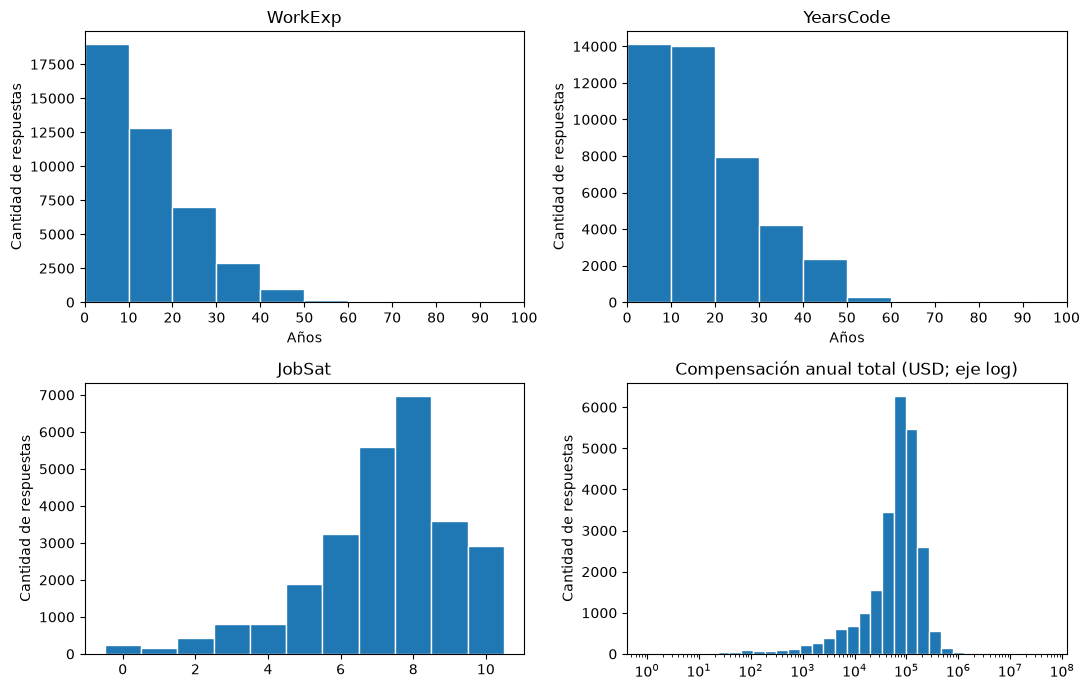

Compensaciones positivas informadas: 23947 | Representadas: 23947


In [9]:

columnas_cuantitativas = ["WorkExp", "YearsCode", "JobSat", "ToolCountWork", "ToolCountPersonal", "ConvertedCompYearly"]
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
# Recorremos las tres variables que se pueden leer bien en escala original.
for ax, col in zip(axes.flat, ["WorkExp", "YearsCode", "JobSat"]):
    intervalos = np.arange(-0.5, 11.5, 1) if col == "JobSat" else range(0, 101, 10)  
    ax.hist(raw_dataset[col].dropna(), bins=intervalos, edgecolor="white") # Contamos respuestas por intervalo.
    if col in ["WorkExp", "YearsCode"]:
     ax.set_xticks(range(0, 101, 10))  #cada 10 años.
     ax.set_xlim(0, 100)              # Mostramos el rango completo.
     ax.set_xlabel("Años")  
    ax.set_title(col) 
    ax.set_ylabel("Cantidad de respuestas")  


# Seleccionamos las compensaciones informadas y positivas segun el describe para el eje logarítmico.
compensacion_eda = raw_dataset.loc[raw_dataset["ConvertedCompYearly"] > 0, "ConvertedCompYearly"]
intervalos_comp = np.logspace(np.log10(compensacion_eda.min()), np.log10(compensacion_eda.max()), 35)
intervalos_comp[0] = compensacion_eda.min()
intervalos_comp[-1] = compensacion_eda.max()

# Guardamos las frecuencias y los límites que efectivamente usa el histograma.
frecuencias_comp, bordes_comp, barras_comp = axes[1, 1].hist(compensacion_eda, bins=intervalos_comp, edgecolor="white")
axes[1, 1].set_xscale("log")
axes[1, 1].set_title("Compensación anual total (USD; eje log)")
axes[1, 1].set_ylabel("Cantidad de respuestas")
plt.tight_layout()
plt.show()

# Comparamos la cantidad disponible con la suma de las frecuencias dibujadas.
print(f"Compensaciones positivas informadas: {len(compensacion_eda)} | Representadas: {int(frecuencias_comp.sum())}")


La experiencia y los años programando se concentran en valores bajos y medios, con una cola hacia la derecha. La satisfacción se concentra cerca de 7–8. La compensación tiene mucha dispersión y asimetría: por eso revisamos sus extremos y distinguimos cuándo una hipótesis pregunta por la media o por la mediana.

### 1.6. Faltantes y completitud

Contamos faltantes por columna y campos completos por persona. Algunas preguntas dependen del perfil o de respuestas anteriores, por lo que un faltante no equivale necesariamente a una respuesta negativa ni a cero.

In [10]:
resumen_nulls = pd.DataFrame({"Nulos": raw_dataset.isna().sum(), "%": raw_dataset.isna().mean() * 100})
resumen_nulls = resumen_nulls.sort_values("Nulos", ascending=False)
print(resumen_nulls.head(10).round(2).to_string())

                      Nulos      %
AIAgentObsWrite       48927  99.46
SOTagsWant Entry      48761  99.13
SOTagsHaveEntry       48733  99.07
AIModelsWantEntry     48716  99.03
AIAgentOrchWrite      48713  99.03
JobSatPoints_15_TEXT  48527  98.65
AIAgentKnowWrite      48425  98.44
AIModelsHaveEntry     48415  98.42
SO_Actions_15_TEXT    48368  98.33
AIAgentExtWrite       48332  98.25


#### Faltantes en las variables del análisis

Además de los campos abiertos, revisamos las variables que intervienen en las hipótesis. Calculamos los porcentajes sobre todas las filas originales, antes de recodificar respuestas desconocidas. Por eso una respuesta de texto como `Prefer not to say` todavía cuenta como informada en esta etapa.

**Por qué barras horizontales:** permiten comparar los porcentajes de faltantes entre variables con nombres largos sobre una misma escala de 0 a 100. La tabla anterior al gráfico muestra las cantidades y el denominador. Los faltantes pueden tener diferentes motivos; no los interpretamos automáticamente como cero ni como ausencia de la característica (Práctica 5, pp. 5–7; Clase 2, pp. 60–62).


Filas de la base original: 49191
                     Nulos  Porcentaje sobre original
Age                      0                       0.00
YearsCode             6149                      12.50
WorkExp               6298                      12.80
NewRole              13664                      27.78
Country              13754                      27.96
AISelect             15471                      31.45
AIAcc                15894                      32.31
JobSat               22521                      45.78
ConvertedCompYearly  25244                      51.32


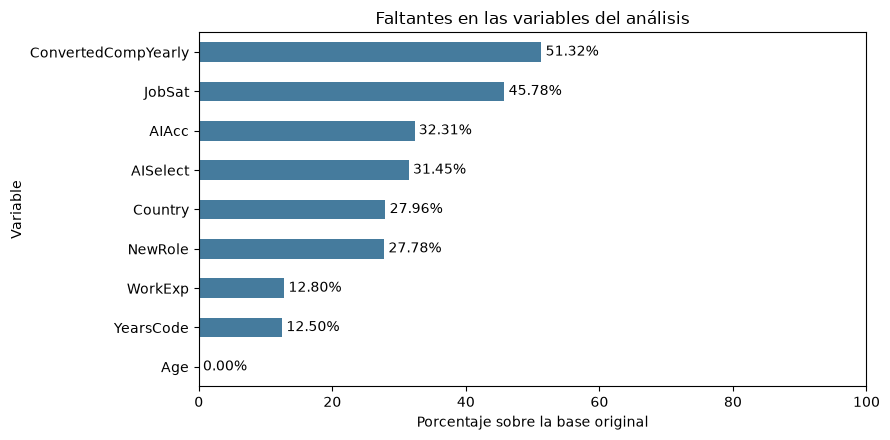

In [59]:
# Elegimos las variables que intervienen en los análisis posteriores.
variables_hipotesis = ["Age", "WorkExp", "YearsCode", "Country", "ConvertedCompYearly", "AISelect", "AIAcc", "JobSat", "NewRole"]
tabla_faltantes_analisis = pd.DataFrame({"Nulos": raw_dataset[variables_hipotesis].isna().sum()})
tabla_faltantes_analisis["Porcentaje sobre original"] = tabla_faltantes_analisis["Nulos"] / len(raw_dataset) * 100
tabla_faltantes_analisis = tabla_faltantes_analisis.sort_values("Porcentaje sobre original")

print("Filas de la base original:", len(raw_dataset))
print(tabla_faltantes_analisis.round(2).to_string())

horizontal = tabla_faltantes_analisis["Porcentaje sobre original"].plot(kind="barh", figsize=(9, 4.5), color="#457b9d")

horizontal.set_xlim(0, 100)
horizontal.set(title="Faltantes en las variables del análisis", xlabel="Porcentaje sobre la base original", ylabel="Variable")

horizontal.bar_label(horizontal.containers[0], labels=[f"{valor:.2f}%" for valor in tabla_faltantes_analisis["Porcentaje sobre original"]], padding=3)
plt.tight_layout()
plt.show()


In [12]:
respuestas_por_encuestado = raw_dataset.drop("ResponseId", axis=1).notna().sum(axis=1)
# Resumimos cuánta información aporta cada registro.
print("Análisis de la cantidad de respuestas por encuestado:")
print(respuestas_por_encuestado.describe().round(1).to_string())

Análisis de la cantidad de respuestas por encuestado:
count    49191.0
mean        80.8
std         46.0
min          2.0
25%         36.0
50%         99.0
75%        120.0
max        155.0


### 1.7. Exploración de variables categóricas relevantes

Revisamos la composición de la muestra y las respuestas sobre IA y cambio laboral con `value_counts()`. La inspección específica de edad, empleo y tamaño de empresa se presenta en la sección 2.4, inmediatamente antes de reemplazar sus respuestas desconocidas.


In [13]:
columnas_categoricas = ["MainBranch", "AISelect", "AIAcc", "NewRole"]
# frecuencias
for col in columnas_categoricas:
    print("\n" + col)  
    print(raw_dataset[col].value_counts(dropna=False).to_string()) 


MainBranch
MainBranch
I am a developer by profession                                                                37467
I am not primarily a developer, but I write code sometimes as part of my work/studies          4894
I am learning to code                                                                          2585
I code primarily as a hobby                                                                    1924
I used to be a developer by profession, but no longer am                                       1325
I work with developers or my work supports developers but am not a developer by profession      996

AISelect
AISelect
Yes, I use AI tools daily                      15883
NaN                                            15471
Yes, I use AI tools weekly                      5958
No, and I don't plan to                         5454
Yes, I use AI tools monthly or infrequently     4628
No, but I plan to soon                          1797

AIAcc
AIAcc
NaN                        

In [14]:
print(raw_dataset["Country"].value_counts().head(5).to_string())
# contamos por separado las respuestas de Argentina, necesarias para la hipótesis A.
print("Respuestas de Argentina:", raw_dataset["Country"].eq("Argentina").sum())

Country
United States of America                                7233
Germany                                                 3025
India                                                   2547
United Kingdom of Great Britain and Northern Ireland    2042
France                                                  1409
Respuestas de Argentina: 222


De la exploración de valores nulos y frecuencias categóricas se desprenden observaciones relevantes para la posterior limpieza:
1. **Columnas con más del 95% de nulos:** Las columnas con mayor cantidad de faltantes (entre 96% y 99,5% de `NaN`) corresponden a campos opcionales de texto libre
2. **Composición de la muestra (`MainBranch`) y nulos estructurales:** Si bien el 76,2% de los encuestados son desarrolladores profesionales (37.467 casos), el conjunto incluye estudiantes, programadores por hobby y ex-desarrolladores. El perfil puede explicar parte de los faltantes en preguntas laborales. También hay preguntas sin respuesta entre profesionales, por lo que no atribuimos todos los faltantes a un único motivo.

La revisión de respuestas desconocidas codificadas como texto se detalla antes de corregirlas, en la sección 2.4.

---

### 1.8. Detección de valores atípicos (outliers) e inconsistencias en los datos
Para evidenciar gráficamente los valores atípicos detectados previamente en `describe()`, utilizamos diagramas de caja (`boxplot`) sobre las variables numéricas principales. Además, verificamos en el raw dateset la existencia de inconsistencias lógicas entre variables (por ejemplo, años de experiencia que superan la edad máxima del intervalo declarado. La comparación WorkExp > YearsCode se inspecciona, pero no prueba una inconsistencia porque WorkExp mide experiencia profesional general, no solo en el hambito de desarrollador profesional).

Usamos boxplots para resumir:  mediana, cuartiles, dispersión y valores separados del conjunto en dos variables medidas en años. Esto permite comparar sus escalas y detectar casos para revisar. Los puntos fuera de los bigotes son señales estadísticas, no demuestran por sí solos que una respuesta sea incorrecta.

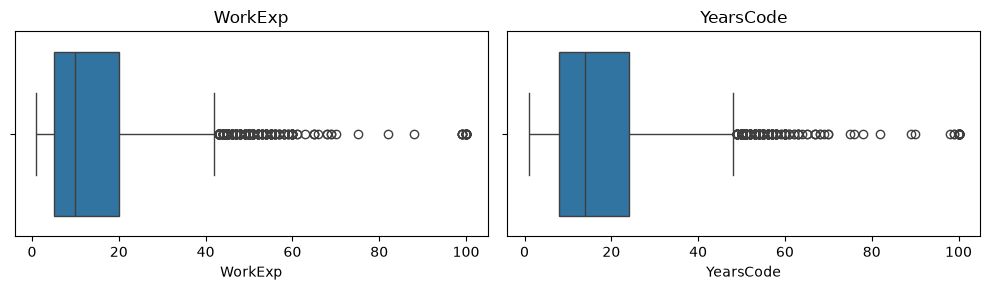

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3))

for ax, col in zip(axes, ["WorkExp", "YearsCode"]):
    sns.boxplot(x=raw_dataset[col], ax=ax)  
    ax.set_title(col)  

plt.tight_layout()
plt.show()

In [16]:
# conteo de casos a revisar 
revision_inicial = pd.Series({
    "WorkExp > 50": (raw_dataset["WorkExp"] > 50).sum(),  
    "YearsCode > 50": (raw_dataset["YearsCode"] > 50).sum(),  
    "WorkExp > YearsCode": (raw_dataset["WorkExp"] > raw_dataset["YearsCode"]).sum(),  # Puede haber experiencia en otra profesión.
    "ToolCountWork > 100": (raw_dataset["ToolCountWork"] > 100).sum(),  
    "Compensación > USD 1.000.000": (raw_dataset["ConvertedCompYearly"] > 1000000).sum(), 
    "Compensación < USD 100": (raw_dataset["ConvertedCompYearly"] < 100).sum(),
})
print(revision_inicial.to_string())

WorkExp > 50                     147
YearsCode > 50                   248
WorkExp > YearsCode             3564
ToolCountWork > 100               95
Compensación > USD 1.000.000      46
Compensación < USD 100           304


Hay registros que declaran más años de experiencia o programación que la edad máxima de su intervalo: esa contradicción sí permite corregir el valor. Otros extremos requieren contexto.

`WorkExp > YearsCode` no prueba un error: como ya se menciono antes, la primera pregunta mide experiencia profesional general y puede incluir otra profesión anterior. Tampoco podemos asumir que un dato salarial extremo invalide la confianza, la edad o la satisfacción informadas por esa persona.

# 2. Operaciones de limpieza

Preservamos `raw_dataset` y trabajamos sobre `preprocessed_dataset`, una copia. Las decisiones se justifican por la definición de las variables y las preguntas que vamos a estudiar.

### 2.1. Columnas fuera del alcance

Excluimos 28 campos abiertos que no utilizaremos. No es por valores invalidos, sino por seleccion. Su cantidad de faltantes es diferente y no es el único motivo de la selección.


In [17]:
preprocessed_dataset = raw_dataset.copy()
columnas_texto_libre = [
    "TechEndorse_13_TEXT", "TechOppose_15_TEXT", "JobSatPoints_15_TEXT", "SO_Actions_15_TEXT",  # Opciones escritas de rankings.
    "LanguagesHaveEntry", "LanguagesWantEntry", "DatabaseHaveEntry", "DatabaseWantEntry",  # Tecnologías ingresadas como texto.
    "PlatformHaveEntry", "PlatformWantEntry", "WebframeHaveEntry", "WebframeWantEntry",  # Plataformas y frameworks abiertos.
    "DevEnvHaveEntry", "DevEnvWantEntry", "SOTagsHaveEntry", "SOTagsWant Entry",  # Entornos y etiquetas abiertas.
    "OfficeStackHaveEntry", "OfficeStackWantEntry", "CommPlatformHaveEntr", "CommPlatformWantEntr",  # Otras aplicaciones escritas.
    "AIModelsHaveEntry", "AIModelsWantEntry", "AIAgentKnowWrite", "AIAgentOrchWrite",  # Modelos y agentes escritos.
    "AIAgentObsWrite", "AIAgentExtWrite", "AIExplain", "AIOpen",  # Respuestas abiertas sobre IA.
]
nulos_textos = preprocessed_dataset[columnas_texto_libre].isna().mean() * 100
print(f"Campos abiertos excluidos: {len(columnas_texto_libre)}; faltantes en estas columnas entre {nulos_textos.min():.1f}% y {nulos_textos.max():.1f}%")
preprocessed_dataset = preprocessed_dataset.drop(columnas_texto_libre, axis=1)

Campos abiertos excluidos: 28; faltantes en estas columnas entre 46.0% y 99.5%


### 2.2. Inspección de registros repetidos e información disponible

Contamos por separado los identificadores repetidos y las coincidencias entre respuestas. En esta encuesta el identificador distingue a las personas: dos encuestados pueden elegir las mismas opciones. Por eso, una coincidencia sin considerar `ResponseId` no alcanza para aplicar `drop_duplicates()` y borrar una de las respuestas.

In [18]:
print("ResponseId repetidos:", raw_dataset["ResponseId"].duplicated().sum())
# Comparamos las respuestas sin usar el identificador como parte de la coincidencia.
columnas_respuestas = raw_dataset.drop("ResponseId", axis=1).columns
# Contamos coincidencias, sin asumir que pertenecen a la misma persona.
cantidad_duplicados = raw_dataset.duplicated(subset=columnas_respuestas).sum()

print("Respuestas coincidentes sin ID:", cantidad_duplicados)

ResponseId repetidos: 0
Respuestas coincidentes sin ID: 1547


Para este estudio excluimos únicamente filas sin datos adicionales a `ResponseId`, `MainBranch` y `Age`. Calculamos la cantidad de campos completos sobre la base original, antes de excluir textos abiertos, para no perder una respuesta válida solo por haber quitado una columna.
Este filtro es una decisión de alcance del grupo y no demuestra que la persona abandonó la encuesta.

Las respuestas coincidentes se conservan. Los registros excluidos por falta de información se cuentan por separado en la celda siguiente.

In [19]:
respuestas_validas = raw_dataset.drop("ResponseId", axis=1).notna().sum(axis=1)
preprocessed_dataset = preprocessed_dataset[respuestas_validas > 2].copy()

print(f"Registros originales: {raw_dataset.shape[0]}")
print(f"Registros conservados: {preprocessed_dataset.shape[0]}")
print(f"Registros excluidos por falta de información adicional: {raw_dataset.shape[0] - preprocessed_dataset.shape[0]}")

Registros originales: 49191
Registros conservados: 48339
Registros excluidos por falta de información adicional: 852


### 2.3. Preselección de atributos de interés
Dado que la encuesta original abarca múltiples (como preguntas sobre el uso interno del foro de Stack Overflow o herramientas de ofimática), realizamos una preselección de variables conservando aquellos atributos que resultan relevantes para el análisis exploratorio y la validación de las hipótesis planteadas.

In [20]:
# Definimos la lista de columnas preseleccionadas para el análisis y las hipótesis
columnas_seleccionadas = [
    "ResponseId", "MainBranch", "Age", "EdLevel", "Employment", 
    "RemoteWork", "OrgSize", "ICorPM", "DevType", "Country",
    # exp y herramientas
    "WorkExp", "YearsCode", "ToolCountWork", "ToolCountPersonal",
    "LanguageHaveWorkedWith", "OpSysProfessional use",
    # Salarios y moneda
    "Currency", "CompTotal", "ConvertedCompYearly",
    # Uso y percepción de IA
    "AISelect", "AIAcc", "AISent", "AIThreat",
    # Satisfacción laboral, aspectos del trabajo y cambio de rol
    "JobSat", "NewRole",
    "JobSatPoints_1", "JobSatPoints_2", "JobSatPoints_3", "JobSatPoints_4",
    "JobSatPoints_5", "JobSatPoints_6", "JobSatPoints_7", "JobSatPoints_8",
    "JobSatPoints_9", "JobSatPoints_10", "JobSatPoints_11", "JobSatPoints_13",
    "JobSatPoints_14", "JobSatPoints_16"
]

preprocessed_dataset = preprocessed_dataset[columnas_seleccionadas].copy()
print(f"Dimensiones tras la preselección de atributos: {preprocessed_dataset.shape}")

Dimensiones tras la preselección de atributos: (48339, 39)


### 2.4. Respuestas desconocidas codificadas como texto

Antes de reemplazar valores, mostramos las categorías de `Age`, `Employment` y `OrgSize` en la base preseleccionada. Esto permite ver qué respuestas representan desconocimiento o una preferencia por no responder.

Después las convertimos a faltantes. Para tamaño de empresa contemplamos tres grafías, incluida una con un carácter Unicode dañado. No imputamos con media, moda ni cero; las respuestas originales siguen disponibles en `raw_dataset`.


In [21]:
# Revisamos los valores de los campos que vamos a recodificar en la siguiente celda.
for col in ["Age", "Employment", "OrgSize"]:
    print("\nCategorías antes de corregir:", col)  # Identificamos el campo de cada listado.
    print(preprocessed_dataset[col].value_counts(dropna=False).to_string())  # Incluimos los faltantes ya existentes.



Categorías antes de corregir: Age
Age
25-34 years old      16228
35-44 years old      13076
18-24 years old       8950
45-54 years old       6198
55-64 years old       2605
65 years or older      932
Prefer not to say      350

Categorías antes de corregir: Employment
Employment
Employed                                                33750
Independent contractor, freelancer, or self-employed     6708
Student                                                  4428
Not employed                                             2227
Retired                                                   708
I prefer not to say                                       518

Categorías antes de corregir: OrgSize
OrgSize
NaN                                                   14161
20 to 99 employees                                     6688
100 to 499 employees                                   6109
Less than 20 employees                                 5600
10,000 or more employees                               4965


In [22]:
# Guardamos los faltantes previos para contar cuántos valores se recodifican.
nulos_texto_antes = preprocessed_dataset[["Age", "Employment", "OrgSize"]].isna().sum()
print("Valores nulos por columna antes:")
print(preprocessed_dataset[["Age", "Employment", "OrgSize"]].isna().sum().to_string())
preprocessed_dataset["Age"] = preprocessed_dataset["Age"].replace("Prefer not to say", np.nan)
preprocessed_dataset["Employment"] = preprocessed_dataset["Employment"].replace("I prefer not to say", np.nan)
preprocessed_dataset["OrgSize"] = preprocessed_dataset["OrgSize"].replace(["I don’t know", "I don't know", "I don\ufffdt know"], np.nan)
print("Valores nulos por columna después:")
print(preprocessed_dataset[["Age", "Employment", "OrgSize"]].isna().sum().to_string())

Valores nulos por columna antes:
Age               0
Employment        0
OrgSize       14161
Valores nulos por columna después:
Age             350
Employment      518
OrgSize       15093


### 2.5. Incompatibilidades y extremos

Si los años de experiencia o programación superan la edad máxima del intervalo declarado, sustituimos solo ese valor por `NaN`. Usamos un diccionario y `map()`, en cuanto a las edades desconocidas y para 65 o más no inventamos un máximo.

Las otras magnitudes extremas se revisan por su significado y su influencia en cada hipótesis. No aplicamos un mismo límite salarial a todos los países ni eliminamos una persona solo por una cantidad de herramientas llamativa.


In [23]:
edad_maxima_por_intervalo = {"18-24 years old": 24, 
                             "25-34 years old": 34, 
                             "35-44 years old": 44,
                             "45-54 years old": 54, 
                             "55-64 years old": 64}

edad_maxima = preprocessed_dataset["Age"].map(edad_maxima_por_intervalo)
inconsistentes_workexp = preprocessed_dataset["WorkExp"] > edad_maxima
inconsistentes_yearscode = preprocessed_dataset["YearsCode"] > edad_maxima
print("Valores incompatibles: WorkExp =", inconsistentes_workexp.sum(), "| YearsCode =", inconsistentes_yearscode.sum())


preprocessed_dataset.loc[inconsistentes_workexp, "WorkExp"] = np.nan
preprocessed_dataset.loc[inconsistentes_yearscode, "YearsCode"] = np.nan
# Guardamos los casos de un siglo declarado para comprobar luego su influencia.
casos_exp_dudosa = preprocessed_dataset[(preprocessed_dataset["WorkExp"] >= 100) | (preprocessed_dataset["YearsCode"] >= 100)].copy()
ids_exp_dudosa = casos_exp_dudosa["ResponseId"]
# Mostramos solo cuántos quedan, en lugar de repetir una tabla extensa.
print("Registros con un siglo declarado que requieren analisis:", len(casos_exp_dudosa))

Valores incompatibles: WorkExp = 53 | YearsCode = 54
Registros con un siglo declarado que requieren analisis: 9


Se corrigieron únicamente incompatibilidades demostrables con la edad. Los nueve registros con 100 años declarados en `WorkExp` o `YearsCode` quedan identificados: como no conocemos el valor correcto y no hay motivo para invalidar automáticamente todas las demás respuestas de esas personas. En la hipótesis de experiencia repetiremos el contraste sin estos casos para comprobar si cambian la conclusión.

#### Cantidades de herramientas declaradas

La pregunta cuenta aplicaciones o plataformas distintas usadas regularmente para el rol principal, excluyendo sistemas operativos y navegadores. Adoptamos el criterio de tratar `ToolCountWork = 10000` como un dato desconocido: su magnitud resulta dudosa para esa definición y no podemos reconstruir la respuesta correcta.

Primero guardamos esos casos y mostramos el valor antes y después del reemplazo. Se modifica únicamente esa columna; las filas y sus demás respuestas se conservan. Los valores de herramientas personales se dejan visibles para revisión, sin aplicarles un corte nuevo.


In [ ]:
pregunta_herramientas = metadatos.loc[metadatos["qname"].eq("ToolCountWork"), "question"].iloc[0]
print("Pregunta original de ToolCountWork:", pregunta_herramientas)

herramientas_trabajo_dudosas = preprocessed_dataset["ToolCountWork"].eq(10000)
casos_herramientas = preprocessed_dataset.loc[herramientas_trabajo_dudosas].copy()
preprocessed_dataset.loc[herramientas_trabajo_dudosas, "ToolCountWork"] = np.nan
tabla_revision_herramientas = pd.DataFrame({"ResponseId": casos_herramientas["ResponseId"], "ToolCountWork antes": casos_herramientas["ToolCountWork"], "ToolCountWork después": preprocessed_dataset.loc[casos_herramientas.index, "ToolCountWork"], "ToolCountPersonal (se conserva)": casos_herramientas["ToolCountPersonal"]})
print("Valores 10000 de ToolCountWork convertidos a faltantes:", int(herramientas_trabajo_dudosas.sum()))
# dejamos visibles los casos detectados y la decisión aplicada a cada uno.
print(tabla_revision_herramientas.to_string(index=False))


Pregunta original de ToolCountWork: For your <b>primary work role</b> (student, developer, or technologist) over the past year:
<br><br>Excluding general operating systems (like Windows or macOS) and web browsers, <b>how many distinct software applications or platforms</b> did you regularly use to create, analyze, manage, or share information in order to do your job?

Please enter a whole number below with no punctuation, or leave blank.
Valores 10000 de ToolCountWork convertidos a faltantes: 15
 ResponseId  ToolCountWork antes  ToolCountWork después  ToolCountPersonal (se conserva)
       5749              10000.0                    NaN                              2.0
       6786              10000.0                    NaN                           1000.0
       6874              10000.0                    NaN                             10.0
       6990              10000.0                    NaN                           1000.0
      21456              10000.0                    Na

La tabla muestra el reemplazo de los valores de trabajo por `NaN`. Las compensaciones, la experiencia y las otras respuestas de esas personas no se modifican por este motivo. El criterio se aplica a toda la base, sin depender de que haya una compensación informada o de que la persona participe después en una hipótesis.


### 2.6. Comprobación de las correcciones

Verificamos que no queden valores que contradigan los límites de edad conocidos. Luego comparamos experiencia y años programando antes y después de las correcciones, sobre las mismas filas conservadas.

**Por qué boxplots comparativos:** permiten observar centro, dispersión y extremos con una caja por estado. Usamos el mismo recorrido de años para que un cambio de escala no exagere las diferencias. La tabla de cantidades permite reconocer las correcciones aunque las cajas cambien poco. Los extremos que no pudieron resolverse con la edad permanecen señalados para controles posteriores (Práctica 5, pp. 14–18).


In [25]:
print("WorkExp incompatible restante:", (preprocessed_dataset["WorkExp"] > edad_maxima).sum())
print("YearsCode incompatible restante:", (preprocessed_dataset["YearsCode"] > edad_maxima).sum())
print("JobSat fuera de 0–10:", (~preprocessed_dataset["JobSat"].between(0, 10) & preprocessed_dataset["JobSat"].notna()).sum())

WorkExp incompatible restante: 0
YearsCode incompatible restante: 0
JobSat fuera de 0–10: 0


 Variable  Antes: valores informados  Después: valores informados  Valores anulados
  WorkExp                      42893                        42840                53
YearsCode                      43042                        42988                54


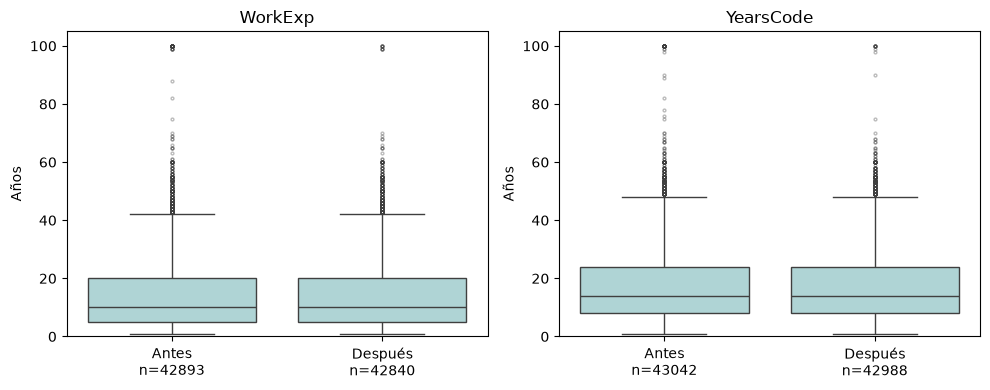

In [ ]:
# Compararemos las variables corregidas usando exactamente las mismas filas antes y después.
control_correcciones = []

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
# comparamos cada columna original con su versión limpia.
for ax, col in zip(axes, ["WorkExp", "YearsCode"]):
    antes = raw_dataset.loc[preprocessed_dataset.index, col]  #a
    despues = preprocessed_dataset[col]  
    comparacion = pd.DataFrame({"Antes": antes, "Después": despues})  
    sns.boxplot(data=comparacion, color="#a8dadc", flierprops={"markersize": 2, "alpha": 0.35}, ax=ax)  
    ax.set_ylim(0, 105)  
    ax.set_xticks([0, 1], labels=[f"Antes\nn={antes.notna().sum()}", f"Después\nn={despues.notna().sum()}"])  
    ax.set(title=col, ylabel="Años")  
    control_correcciones.append({"Variable": col, "Antes: valores informados": int(antes.notna().sum()), "Después: valores informados": int(despues.notna().sum()), "Valores anulados": int((antes.notna() & despues.isna()).sum())})  

tabla_control_correcciones = pd.DataFrame(control_correcciones)
# Mostramos la tabla antes de presentar la figura.
print(tabla_control_correcciones.to_string(index=False))
plt.tight_layout()
plt.show()


### 2.7. Preprocesamiento de la escala ordinal de confianza en la IA (`AIAcc`)
Mientras que en atributos por intervalos como `Age` resulta más claro conservar las etiquetas del intervalo original (ya que luego de limpiar `"Prefer not to say"` sus rangos quedan ordenados naturalmente de `"18-24 years old"` a `"65 years or older"`), en la variable `AIAcc` (confianza en la precisión de la IA) el orden alfabético mezcla los extremos (`"Highly distrust"` queda junto a `"Highly trust"`).

Siguiendo lo visto en la práctica, conservamos la columna original y creamos una variable llamada `aiacc_ordinal` mediante el método `map()`, asignando valores de numericos desde la menor hasta la mayor confianza para poder analizar su relación con la experiencia profesional.

In [27]:
print("Intervalos de Age conservados y ordenados:")
print(preprocessed_dataset["Age"].value_counts().sort_index())
# mapeo
aiacc_map = {
    "Highly distrust": 1,
    "Somewhat distrust": 2,
    "Neither trust nor distrust": 3,
    "Somewhat trust": 4,
    "Highly trust": 5
}
print("\nConteo de aiacc:")
print(preprocessed_dataset["AIAcc"].value_counts().sort_index())
preprocessed_dataset["aiacc_ordinal"] = preprocessed_dataset["AIAcc"].map(aiacc_map)
print("\nConteo de aiacc_ordinal:")
print(preprocessed_dataset["aiacc_ordinal"].value_counts().sort_index())

Intervalos de Age conservados y ordenados:
Age
18-24 years old       8950
25-34 years old      16228
35-44 years old      13076
45-54 years old       6198
55-64 years old       2605
65 years or older      932
Name: count, dtype: int64

Conteo de aiacc:
AIAcc
Highly distrust               6533
Highly trust                  1048
Neither trust nor distrust    7162
Somewhat distrust             8685
Somewhat trust                9869
Name: count, dtype: int64

Conteo de aiacc_ordinal:
aiacc_ordinal
1.0    6533
2.0    8685
3.0    7162
4.0    9869
5.0    1048
Name: count, dtype: int64


### 2.8. Creación de variables derivadas
Creamos una nueva variable para almacenar si un usuario utiliza o no la IA a diario utilizando `apply()` y una función `lambda` para crear `is_daily_ai_user`, sin convertir los faltantes de `AISelect` en respuestas negativas.

También creamos `considers_new_role` mediante un diccionario y `map()` (Práctica 4, sección 6). Agrupamos las respuestas en tres categorías nominales: no consideró cambiar, lo consideró y ya realizó una transición. Las transiciones no se mezclan con la intención de cambiar; conservamos `NewRole` para no perder el detalle original.

In [28]:
preprocessed_dataset["is_daily_ai_user"] = preprocessed_dataset["AISelect"].apply(
    lambda x: True if x == "Yes, I use AI tools daily" else (False if pd.notna(x) else np.nan)
)
print("Conteo de is_daily_ai_user:")
print(preprocessed_dataset["is_daily_ai_user"].value_counts(dropna=False))
newrol_map = {
    "I have neither consider or transitioned into a new career or industry": "No considero",
    "I have somewhat considered changing my career and/or the industry I work in": "Considero",
    "I have strongly considered changing my career and/or the industry I work in": "Considero",
    "I have transitioned into a new career and/or industry voluntarily": "Transiciono",
    "I have transitioned into a new career and/or industry involuntarily": "Transiciono"
}
preprocessed_dataset["considers_new_role"] = preprocessed_dataset["NewRole"].map(newrol_map)
print("Conteo de considers_new_role:")
print(preprocessed_dataset["considers_new_role"].value_counts(dropna=False))
print("Dimensiones después de crear las variables:", preprocessed_dataset.shape)
preprocessed_dataset.head()

Conteo de is_daily_ai_user:
is_daily_ai_user
False    17837
True     15883
NaN      14619
Name: count, dtype: int64
Conteo de considers_new_role:
considers_new_role
No considero    16205
Considero       15486
NaN             12812
Transiciono      3836
Name: count, dtype: int64
Dimensiones después de crear las variables: (48339, 42)


,ResponseId,MainBranch,Age,EdLevel,Employment,RemoteWork,OrgSize,ICorPM,DevType,Country,WorkExp,YearsCode,ToolCountWork,ToolCountPersonal,LanguageHaveWorkedWith,OpSysProfessional use,Currency,CompTotal,ConvertedCompYearly,AISelect,AIAcc,AISent,AIThreat,JobSat,NewRole,JobSatPoints_1,JobSatPoints_2,JobSatPoints_3,JobSatPoints_4,JobSatPoints_5,JobSatPoints_6,JobSatPoints_7,JobSatPoints_8,JobSatPoints_9,JobSatPoints_10,JobSatPoints_11,JobSatPoints_13,JobSatPoints_14,JobSatPoints_16,aiacc_ordinal,is_daily_ai_user,considers_new_role
0,1,I am a developer by profession,25-34 years old,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",Employed,Remote,20 to 99 employees,People manager,"Developer, mobile",Ukraine,8.0,14.0,7.0,3.0,Bash/Shell (all shells);Dart;SQL,Windows;MacOS;Android;iOS;iPadOS,EUR European Euro,52800.0,61256.0,"Yes, I use AI tools monthly or infrequently",Neither trust nor distrust,Indifferent,I'm not sure,10.0,I have neither consider or transitioned into a...,3.0,1.0,4.0,9.0,5.0,10.0,12.0,11.0,2.0,6.0,7.0,13.0,14.0,8.0,3.0,False,No considero
1,2,I am a developer by profession,25-34 years old,"Associate degree (A.A., A.S., etc.)",Employed,"Hybrid (some in-person, leans heavy to flexibi...",500 to 999 employees,Individual contributor,"Developer, back-end",Netherlands,2.0,10.0,6.0,5.0,Java,MacOS,EUR European Euro,90000.0,104413.0,"Yes, I use AI tools weekly",Neither trust nor distrust,Indifferent,I'm not sure,9.0,I have transitioned into a new career and/or i...,10.0,8.0,3.0,9.0,12.0,1.0,6.0,2.0,11.0,4.0,7.0,13.0,14.0,5.0,3.0,False,Transiciono
2,3,I am a developer by profession,35-44 years old,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)","Independent contractor, freelancer, or self-em...",NaN,NaN,NaN,"Developer, front-end",Ukraine,10.0,12.0,3.0,3.0,Dart;HTML/CSS;JavaScript;TypeScript,MacOS,UAH Ukrainian hryvnia,2214000.0,53061.0,"Yes, I use AI tools daily",Somewhat trust,Favorable,No,8.0,I have transitioned into a new career and/or i...,9.0,6.0,7.0,11.0,8.0,12.0,1.0,5.0,2.0,4.0,3.0,13.0,14.0,10.0,4.0,True,Transiciono
3,4,I am a developer by profession,35-44 years old,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Employed,Remote,"10,000 or more employees",Individual contributor,"Developer, back-end",Ukraine,4.0,5.0,NaN,NaN,Java;Kotlin;SQL,Windows;Ubuntu,EUR European Euro,31200.0,36197.0,"Yes, I use AI tools weekly",Somewhat trust,Favorable,No,6.0,I have neither consider or transitioned into a...,1.0,2.0,4.0,5.0,6.0,7.0,8.0,9.0,10.0,11.0,12.0,13.0,14.0,3.0,4.0,False,No considero
4,5,I am a developer by profession,35-44 years old,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)","Independent contractor, freelancer, or self-em...",NaN,NaN,NaN,Engineering manager,Ukraine,21.0,22.0,4.0,3.0,C;C#;C++;Delphi;HTML/CSS;Java;JavaScript;Lua;P...,Windows;Ubuntu;Debian,USD United States dollar,60000.0,60000.0,"Yes, I use AI tools weekly",Neither trust nor distrust,Favorable,No,7.0,I have neither consider or transitioned into a...,9.0,4.0,11.0,13.0,14.0,8.0,6.0,5.0,7.0,2.0,1.0,12.0,10.0,3.0,3.0,False,No considero


### 2.9. Resumen de las operaciones de limpieza

Reunimos los cambios calculados durante esta sección. La columna `Unidad` distingue filas excluidas, valores recodificados y columnas seleccionadas o creadas; las cantidades no deben sumarse como si todas representaran personas eliminadas. Los extremos que solo se señalaron para revisión no se cuentan como valores corregidos.


In [ ]:
nulos_texto_despues = preprocessed_dataset[["Age", "Employment", "OrgSize"]].isna().sum()
recodificados_texto = nulos_texto_despues - nulos_texto_antes
# Identificamos las columnas nuevas por comparación con los nombres de la base original.
variables_creadas = [col for col in preprocessed_dataset.columns if col not in raw_dataset.columns]

resumen_limpieza = pd.DataFrame([
    {"Operación": "Registros sin información adicional excluidos", "Cantidad": len(raw_dataset) - len(preprocessed_dataset), "Unidad": "filas"},
    {"Operación": "Campos abiertos fuera del alcance", "Cantidad": len(columnas_texto_libre), "Unidad": "columnas excluidas"},
    {"Operación": "Atributos originales seleccionados", "Cantidad": len(columnas_seleccionadas), "Unidad": "columnas conservadas"},
    {"Operación": "Edad desconocida convertida a faltante", "Cantidad": recodificados_texto["Age"], "Unidad": "valores"},
    {"Operación": "Empleo desconocido convertido a faltante", "Cantidad": recodificados_texto["Employment"], "Unidad": "valores"},
    {"Operación": "Tamaño de empresa desconocido convertido a faltante", "Cantidad": recodificados_texto["OrgSize"], "Unidad": "valores"},
    {"Operación": "WorkExp incompatible con edad convertido a faltante", "Cantidad": inconsistentes_workexp.sum(), "Unidad": "valores"},
    {"Operación": "YearsCode incompatible con edad convertido a faltante", "Cantidad": inconsistentes_yearscode.sum(), "Unidad": "valores"},
    {"Operación": "ToolCountWork = 10000 convertido a faltante", "Cantidad": herramientas_trabajo_dudosas.sum(), "Unidad": "valores"},
    {"Operación": "Variables derivadas creadas", "Cantidad": len(variables_creadas), "Unidad": "columnas"},
])

print("Base original:", raw_dataset.shape, "| Base limpia:", preprocessed_dataset.shape)
print(resumen_limpieza.to_string(index=False))
print("Variables creadas:", variables_creadas)


Base original: (49191, 172) | Base limpia: (48339, 42)
                                            Operación  Cantidad               Unidad
        Registros sin información adicional excluidos       852                filas
                    Campos abiertos fuera del alcance        28   columnas excluidas
                   Atributos originales seleccionados        39 columnas conservadas
               Edad desconocida convertida a faltante       350              valores
             Empleo desconocido convertido a faltante       518              valores
  Tamaño de empresa desconocido convertido a faltante       932              valores
  WorkExp incompatible con edad convertido a faltante        53              valores
YearsCode incompatible con edad convertido a faltante        54              valores
          ToolCountWork = 10000 convertido a faltante        15              valores
                          Variables derivadas creadas         3             columnas
Variables 

#### Guardado del conjunto limpio

Guardamos la base después de corregir incompatibilidades y crear las variables derivadas. Los filtros de perfil, faltantes o sensibilidad se aplican solo a cada análisis; no borran esas personas del archivo.

In [30]:
print("Dataset Base:", raw_dataset.shape)
print("Base limpia:", preprocessed_dataset.shape)
preprocessed_dataset.to_pickle("dataset_limpio_2.pkl")

Dataset Base: (49191, 172)
Base limpia: (48339, 42)


# 3. Hipótesis del grupo

Delimitamos el estudio a quienes se identificaron como **desarrolladores profesionales**. La base conserva los demás perfiles; este filtro se aplica únicamente a las hipótesis. En cada contraste usamos las respuestas disponibles para sus variables y mostramos el tamaño de la muestra.

### 3.1. Univariada: confianza en la precisión de la IA

**Planteo:** menos del 10% de quienes respondieron `AIAcc` tiene confianza alta (`Highly trust`) y más del 40% expresa desconfianza (`Somewhat distrust` o `Highly distrust`).

**Motivo:** usar un asistente no implica confiar plenamente en su resultado. Nos interesa ver si la revisión crítica de estas herramientas se refleja en la confianza declarada. La encuesta no permite determinar el motivo de la respuesta de cada persona.

### 3.2. Bivariada: brecha de compensación entre mercados laborales

**Planteo:** la mediana de compensación anual total en USD de Estados Unidos supera el doble de la de India.

**Motivo:** buscamos cuantificar cuánto cambia la compensación central entre las respuestas de dos mercados laborales, en lugar de interpretar un único salario global. Expresamos ambos montos en USD y usamos la mediana por la asimetría y los extremos. El cociente entre medianas permite describir el tamaño de la brecha nominal. La comparación no mide poder adquisitivo ni aísla el efecto del país, el costo de vida, la experiencia o el tipo de empresa.

### 3.3. Multivariada: edad, experiencia, compensación y uso de IA

**Planteo:** el grupo de **25 años o más**, comparado con el de **18–24 años**, tiene mayor experiencia mediana, mayor compensación mediana y menor proporción de uso diario de IA.

**Motivo:** esperamos encontrar diferencias de trayectoria y hábitos entre esos perfiles. Reunimos los rangos mayores en un solo grupo para contrastar un perfil de 25 años o más frente al de 18–24. La interpretación se refiere a esos dos grupos definidos.

Evaluamos las tres condiciones sobre las mismas personas con las cuatro respuestas disponibles. Es una comparación de un perfil con varias variables; no es un modelo que controle los efectos de país, rol o empresa. `WorkExp` representa experiencia profesional general.

### 3.4. Grupo de análisis

Las hipótesis se refieren a desarrolladores profesionales. Usamos la categoría de `MainBranch` para delimitar ese grupo de forma consistente; no interpretamos que los demás perfiles tengan respuestas inválidas. El archivo limpio conserva todos los perfiles.

Dentro de ese grupo, cada análisis requiere respuestas diferentes. Por eso mostramos el total disponible y aplicamos los filtros específicos cuando presentamos cada hipótesis. Las tablas siguientes también permiten seguir los registros señalados por herramientas sin confundir una corrección de un campo con la eliminación de una persona.


In [ ]:
# Definimos el perfil profesional después de presentar el alcance de las hipótesis.
perfil_profesional = "I am a developer by profession"
# Creamos una vista para los análisis sin borrar los otros perfiles del archivo limpio.
datos_profesionales = preprocessed_dataset[preprocessed_dataset["MainBranch"].eq(perfil_profesional)].copy()
print("Registros en la base limpia:", len(preprocessed_dataset), "| Desarrolladores profesionales:", len(datos_profesionales))
casos_herramientas_profesionales = casos_herramientas[casos_herramientas["MainBranch"].eq(perfil_profesional)]
candidatos_herramientas = casos_herramientas_profesionales.dropna(subset=["ConvertedCompYearly"])
print("Casos señalados por herramientas:", len(casos_herramientas), "| Profesionales:", len(casos_herramientas_profesionales), "| Con compensación:", len(candidatos_herramientas))


Registros en la base limpia: 48339 | Desarrolladores profesionales: 36896
Casos señalados por herramientas: 15 | Profesionales: 10 | Con compensación informada: 7


In [ ]:
# Conservamos el mismo criterio de ordenamiento por identificador para revisar los casos del subconjunto.
ejemplo_herramientas = candidatos_herramientas.sort_values("ResponseId").head(7)
seguimiento_herramientas = ejemplo_herramientas[["ResponseId", "ToolCountWork", "ToolCountPersonal", "WorkExp", "ConvertedCompYearly"]].rename(columns={"ToolCountWork": "ToolCountWork antes"}).copy()
# Recuperamos el dato corregido de la base limpia usando los mismos índices.
seguimiento_herramientas["ToolCountWork limpio"] = preprocessed_dataset.loc[ejemplo_herramientas.index, "ToolCountWork"]
# Dejamos visible que las compensaciones siguen disponibles aunque el campo de herramientas sea desconocido.
print(seguimiento_herramientas.to_string(index=False))


 ResponseId  ToolCountWork antes  ToolCountPersonal  WorkExp  ConvertedCompYearly  ToolCountWork limpio
       6786              10000.0             1000.0     14.0             110000.0                   NaN
      21456              10000.0             1000.0      NaN             444449.0                   NaN
      26582              10000.0             1000.0     19.0             218000.0                   NaN
      30279              10000.0             1000.0     12.0              84691.0                   NaN
      32873              10000.0             1000.0     42.0             295000.0                   NaN
      36992              10000.0                NaN     10.0              45879.0                   NaN
      44358              10000.0             1000.0      8.0              54611.0                   NaN


El subconjunto con compensación informada es una vista de seguimiento, no el criterio usado para limpiar herramientas. La corrección se aplicó antes a todos los casos señalados. A continuación, cada hipótesis presenta sus datos y controles específicos antes de interpretar los resultados.


# 4. Contrastes de hipótesis

La primera hipótesis se evalúa de forma descriptiva mediante agrupaciones y porcentajes. Las reglas de contrastación siguientes se aplican a las demás hipótesis.

Seguimos esta secuencia: **H₀/H₁ → nivel de significancia → supuestos → test → resultado e interpretación**. Fijamos **α = 0,05** antes de contrastar. Si p < α rechazamos H₀; si p ≥ α no tenemos evidencia suficiente para rechazarla. Esto último no prueba que H₀ sea verdadera.

Cada persona aporta una respuesta y los grupos son excluyentes; asumimos independencia entre encuestados. La encuesta es voluntaria y los faltantes pueden depender del perfil. Por eso, los p-valores son resultados bajo esos supuestos y no corrigen un sesgo de selección ni permiten generalizar automáticamente a todos los desarrolladores.

Elegimos el test por el parámetro de la hipótesis. ANOVA compara medias de varios grupos y requiere revisar normalidad y varianzas. Para una hipótesis sobre medianas usamos el test de la mediana; para categorías, proporciones o independencia, sus contrastes correspondientes. No inferimos significancia por el aspecto de los gráficos.

In [33]:
alpha = 0.05

orden_likert = ["Highly distrust", "Somewhat distrust", "Neither trust nor distrust", "Somewhat trust", "Highly trust"]
etiquetas_confianza = ["Desconfía mucho", "Desconfía algo", "Neutral", "Confía algo", "Confía mucho"]


def mostrar_p(valor):
    return "<0,001" if valor < 0.001 else f"{valor:.3f}"  # Evitamos imprimir como cero un p-valor muy pequeño.

print("Desarrolladores profesionales disponibles:", len(datos_profesionales))

Desarrolladores profesionales disponibles: 36896


### 4.1. Confianza en la IA: agrupamiento y porcentajes

Evaluamos las dos condiciones del planteo con las respuestas de `AIAcc`, sin aplicar un test estadístico. Trabajamos con desarrolladores profesionales que respondieron esta pregunta; los faltantes quedan fuera del denominador.

Primero mostramos las cinco categorías originales. Después las reunimos en tres grupos:

| Grupo | Respuestas que incluye |
|---|---|
| Confianza alta | `Highly trust` |
| Desconfianza | `Somewhat distrust` y `Highly distrust` |
| Resto | `Neither trust nor distrust` y `Somewhat trust` |

Cada persona pertenece a un solo grupo. Calculamos **porcentaje = cantidad del grupo / total de respuestas válidas × 100**. Para que el planteo se cumpla en estas respuestas, la confianza alta debe ser menor al 10% y la desconfianza mayor al 40%. La tabla muestra ambos porcentajes y la comparación con cada límite.

**Por qué usamos este procedimiento:** la pregunta se puede evaluar descriptivamente contando las categorías y agrupándolas según el planteo. No asignamos distancias numéricas a los niveles de confianza. Utilizamos `map()` para definir los grupos y `groupby()` para contar sus respuestas, como en las prácticas.

**Alcance:** la conclusión describe a los encuestados analizados. No calculamos p-valores ni hablamos de significancia estadística; tampoco extendemos automáticamente los porcentajes a todos los desarrolladores.


**Por qué un gráfico de barras:** los tres grupos son categorías que reúnen todas las respuestas válidas. Las barras permiten comparar sus porcentajes sobre el mismo total. Mostramos antes los conteos originales y agrupados para que se pueda reconstruir cada barra 


**Dos lecturas de la misma conclusión:** el primer gráfico muestra cómo se reparten todas las respuestas entre los tres grupos. El segundo compara los porcentajes de interés con los límites del planteo (10% y 40%). Las barras de referencia son umbrales fijados por el grupo, no otro conjunto de encuestados


In [ ]:
# Seleccionamos los profesionales que respondieron AIAcc sin modificar la base limpia.
datos_confianza = datos_profesionales.dropna(subset=["AIAcc"]).copy()
aiacc_valida = datos_confianza["AIAcc"]
n_aiacc = len(aiacc_valida)
# Contamos las categorías originales respetando el orden de menor a mayor confianza.
conteo_aiacc = aiacc_valida.value_counts().reindex(orden_likert, fill_value=0)
porcentajes_aiacc = conteo_aiacc / n_aiacc * 100

tabla_frecuencias_aiacc = pd.DataFrame({"Cantidad": conteo_aiacc, "Porcentaje": porcentajes_aiacc})
# Informamos el total analizado y cuántas personas no respondieron esta pregunta.
print("Respuestas válidas:", n_aiacc, "| Sin AIAcc:", datos_profesionales["AIAcc"].isna().sum())
print(tabla_frecuencias_aiacc.round(2).to_string())


mapa_confianza = {
    "Highly trust": "Confianza alta",  
    "Somewhat distrust": "Desconfianza",  
    "Highly distrust": "Desconfianza", 
    "Neither trust nor distrust": "Resto", 
    "Somewhat trust": "Resto",  
}
datos_confianza["Grupo_confianza"] = datos_confianza["AIAcc"].map(mapa_confianza)
# Fijamos el orden que tendrán la tabla agrupada y el gráfico.
orden_grupos_confianza = ["Confianza alta", "Desconfianza", "Resto"]
conteo_grupos_aiacc = datos_confianza.groupby("Grupo_confianza")["ResponseId"].count().reindex(orden_grupos_confianza, fill_value=0)
tabla_agrupada_aiacc = pd.DataFrame({"Cantidad": conteo_grupos_aiacc})
# Calculamos el porcentaje de cada grupo usando el mismo denominador.
tabla_agrupada_aiacc["Porcentaje"] = tabla_agrupada_aiacc["Cantidad"] / n_aiacc * 100
# Separamos visualmente la tabla agrupada de las categorías originales.
print("\nRespuestas agrupadas:")
# Mostramos los numeros que después se representaran en el gráfico.
print(tabla_agrupada_aiacc.round(2).to_string())


cant_alta = tabla_agrupada_aiacc.loc["Confianza alta", "Cantidad"]
cant_desconfianza = tabla_agrupada_aiacc.loc["Desconfianza", "Cantidad"]
# Conservamos ambas proporciones para reutilizarlas en la interpretación y el resumen final.
p_alta, p_desconfianza = cant_alta / n_aiacc, cant_desconfianza / n_aiacc
# Comparamos la proporción de confianza alta con el límite del 10%.
cumple_alta = p_alta < 0.10
# Comparamos la proporción de desconfianza con el límite del 40%.
cumple_desconfianza = p_desconfianza > 0.40
# El planteo completo se cumple solo si se cumplen las dos condiciones.
cumple_h1 = cumple_alta and cumple_desconfianza
# Dejamos visibles los porcentajes y las comparaciones; no son resultados de un test estadístico.
resultados_h1 = pd.DataFrame({"Condición": ["Confianza alta <10%", "Desconfianza >40%"], "Observado (%)": [100 * p_alta, 100 * p_desconfianza], "Se cumple en estas respuestas": [cumple_alta, cumple_desconfianza]})
# Mostramos la comprobación descriptiva de los dos límites.
print("\nComprobación de las condiciones:")
# Presentamos los porcentajes redondeados sin modificar los valores usados para comparar.
print(resultados_h1.round(2).to_string(index=False))


Respuestas válidas: 25739 | Sin AIAcc: 11157
                            Cantidad  Porcentaje
AIAcc                                           
Highly distrust                 5058       19.65
Somewhat distrust               6767       26.29
Neither trust nor distrust      5576       21.66
Somewhat trust                  7632       29.65
Highly trust                     706        2.74

Respuestas agrupadas:
                 Cantidad  Porcentaje
Grupo_confianza                      
Confianza alta        706        2.74
Desconfianza        11825       45.94
Resto               13208       51.32

Comprobación de las condiciones:
          Condición  Observado (%)  Se cumple en estas respuestas
Confianza alta <10%           2.74                           True
  Desconfianza >40%          45.94                           True


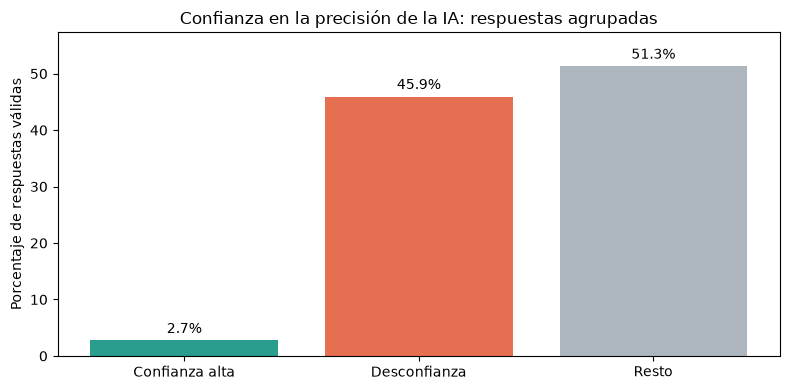

                Observado  Umbral del planteo
Confianza alta       2.74                  10
Desconfianza        45.94                  40


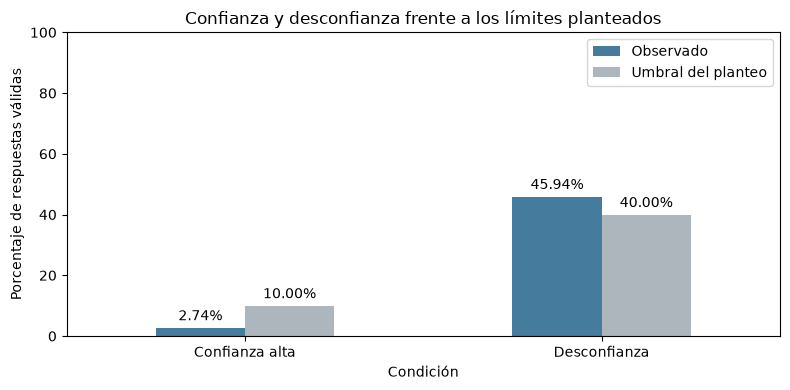

Lectura: la confianza alta representa el 2.74% de las respuestas válidas y la desconfianza, el 45.94%.
Las dos condiciones se cumplen en las respuestas analizadas.
Esto describe confianza declarada: no permite saber si cada persona revisa el código generado ni por qué confía o desconfía.


In [ ]:
# Usamos los porcentajes de la tabla agrupada para que el gráfico muestre los mismos resultados.
porcentajes_grupos_aiacc = tabla_agrupada_aiacc["Porcentaje"]

fig, ax = plt.subplots(figsize=(8, 4))
barras = ax.bar(orden_grupos_confianza, porcentajes_grupos_aiacc, color=["#2a9d8f", "#e76f51", "#adb5bd"])
ax.bar_label(barras, labels=[f"{valor:.1f}%" for valor in porcentajes_grupos_aiacc], padding=3)
ax.set_ylim(0, porcentajes_grupos_aiacc.max() + 6)
ax.set_title("Confianza en la precisión de la IA: respuestas agrupadas")
ax.set_ylabel("Porcentaje de respuestas válidas")
plt.tight_layout()

plt.show()

comparacion_limites_ia = pd.DataFrame({"Observado": [100 * p_alta, 100 * p_desconfianza], "planteo": [10, 40]}, index=["Confianza alta", "Desconfianza"])
print(comparacion_limites_ia.round(2).to_string())
ax = comparacion_limites_ia.plot(kind="bar", figsize=(8, 4), color=["#43799b", "#adb5bd"], rot=0)

for cont, columna in zip(ax.containers, comparacion_limites_ia.columns):
    ax.bar_label(cont, labels=[f"{valor:.2f}%" for valor in comparacion_limites_ia[columna]], padding=3)  # Identificamos la magnitud representada.

ax.set_ylim(0, 100)
ax.set(title="Confianza y desconfianza frente a los límites planteados", xlabel="Condición", ylabel="Porcentaje de respuestas válidas")
plt.tight_layout()
plt.show()


print(f"Lectura: la confianza alta representa el {100 * p_alta:.2f}% de las respuestas válidas y la desconfianza, el {100 * p_desconfianza:.2f}%.")
print("Las dos condiciones se cumplen en las respuestas analizadas." if cumple_h1 else "Las dos condiciones no se cumplen simultáneamente en las respuestas analizadas.")
print("Esto describe confianza declarada: no permite saber si cada persona revisa el código generado ni por qué confía o desconfía.")


### 4.2. Brecha de compensación entre mercados: Estados Unidos e India

El objetivo es cuantificar la brecha nominal entre las compensaciones centrales declaradas en ambos mercados. Presentamos cantidades y medianas en USD; no interpretamos esta comparación como una medida del costo de vida ni del poder adquisitivo.

**H₀:** mediana_USA = 2 × mediana_India. **H₁:** son distintas.

El planteo del grupo propone que la de Estados Unidos es mayor. Usamos un contraste bilateral contra el doble y leemos su resultado junto con la dirección y el cociente de las medianas observadas. Rechazar la igualdad en el sentido contrario no apoyaría nuestra hipótesis.

El **test de la mediana**, compara las cantidades por encima y por debajo de la mediana conjunta. Multiplicamos los valores de India por dos solo para este contraste; así probamos el umbral que realmente planteamos. No usamos un t-test, porque la pregunta está formulada sobre medianas. El test no exige normalidad y evita que la magnitud de unas pocas compensaciones millonarias domine la comparación.

El contraste es **bilateral**; no presentamos su p-valor como si proviniera de una prueba unilateral. Exigir rechazo bilateral y la dirección esperada es un criterio conservador para sostener el planteo direccional.

Antes del resultado reconstruimos la tabla de valores por encima y por debajo de la mediana conjunta, como en la Clase 5, p. 33. Así se ve de dónde sale la tabla que usa el test.

Por qué un boxplot por país: la hipótesis compara medianas y el boxplot muestra ese centro, el IQR y la dispersión. Usamos eje logarítmico para conservar todos los extremos sin recortar datos. El dibujo acompaña al contraste, no lo reemplaza 

Por qué también barras de medianas: el boxplot conserva la distribución y los extremos; las barras muestran en escala lineal la medida central que compara la hipótesis. Los tamaños de cada grupo y el cociente se calculan desde las mismas series. Las barras resumen medianas, no todas las compensaciones individuale


In [ ]:
df_paises = datos_profesionales[datos_profesionales["Country"].isin(["United States of America", "India"])].dropna(subset=["ConvertedCompYearly"]).copy()
df_paises = df_paises[df_paises["ConvertedCompYearly"] > 0].copy()
sueldos_usa = df_paises.loc[df_paises["Country"].eq("United States of America"), "ConvertedCompYearly"]
sueldos_india = df_paises.loc[df_paises["Country"].eq("India"), "ConvertedCompYearly"]
tabla_paises = df_paises.groupby("Country")["ConvertedCompYearly"].agg(n="count", mediana_USD="median")
ratio_mediana = sueldos_usa.median() / sueldos_india.median()
print(tabla_paises.round(2).to_string())
# El cociente expresa cuántas veces representa una mediana respecto de la otra.
print(f"Cociente de medianas USA/India: {ratio_mediana:.2f}")


                             n  mediana_USD
Country                                    
India                      943      18598.0
United States of America  4376     150000.0
Cociente de medianas USA/India: 8.07


#### Revisión de compensaciones extremas de los mercados comparados

Buscamos el mayor importe informado de cada país mediante filtros y ordenamientos. Mostramos también la moneda y el monto declarado para que las observaciones sobre esos extremos puedan comprobarse en los datos.


In [ ]:
datos_india = df_paises[df_paises["Country"].eq("India")]
ejemplo_india = datos_india.sort_values(["ConvertedCompYearly", "ResponseId"], ascending=[False, True]).head(1)

datos_usa = df_paises[df_paises["Country"].eq("United States of America")]
ejemplo_usa = datos_usa.sort_values(["ConvertedCompYearly", "ResponseId"], ascending=[False, True]).head(1)

extremos_mercados = pd.concat([ejemplo_usa.assign(Criterio="Máximo de Estados Unidos"), ejemplo_india.assign(Criterio="Máximo de India")])
print(extremos_mercados[["Criterio", "ResponseId", "Currency", "CompTotal", "ConvertedCompYearly", "WorkExp"]].to_string(index=False))


                Criterio  ResponseId                 Currency   CompTotal  ConvertedCompYearly  WorkExp
Máximo de Estados Unidos       10026 USD United States dollar   9000000.0            9000000.0      2.0
         Máximo de India       24901         INR Indian rupee 820000000.0            9531653.0      1.0


Estos importes muestran la distancia de los extremos respecto del centro de cada mercado. Una compensación muy alta no permite reconstruir un valor alternativo ni invalida las otras respuestas de la persona. Conservamos los importes informados en el análisis principal y comprobamos por separado si la diferencia central depende de los valores señalados por IQR.


#### Control de sensibilidad por país

Calculamos los límites **Q1 − 1,5 × IQR** y **Q3 + 1,5 × IQR** dentro de cada país, para no mezclar distribuciones salariales diferentes. Son señales estadísticas para el control auxiliar; no una regla para borrar las filas de la base. El contraste posterior informa tanto el resultado principal como la comprobación sin esas señales (Clase 3, pp. 9–12).


In [38]:
revision_compensacion = []

for pais in ["United States of America", "India"]:
    sueldos = datos_profesionales.loc[datos_profesionales["Country"].eq(pais), "ConvertedCompYearly"].dropna()  
    q1, q3 = sueldos.quantile([0.25, 0.75])
    iqr = q3 - q1 
    limite_inferior, limite_superior = q1 - 1.5 * iqr, q3 + 1.5 * iqr  
    atipicos = ~sueldos.between(limite_inferior, limite_superior) 
    revision_compensacion.append({"País": pais, "n": len(sueldos), "atipicos por IQR": int(atipicos.sum()), "Mediana en USD": sueldos.median(), "Limite inferior": limite_inferior, "Limite superior": limite_superior})  # Guardamos el diagnóstico, sin quitar filas.

revision_compensacion = pd.DataFrame(revision_compensacion).set_index("País")
print(revision_compensacion.round(2).to_string())

                             n  atipicos por IQR  Mediana en USD  Limite inferior  Limite superior
País                                                                                              
United States of America  4376               260        150000.0         -25000.0         335000.0
India                      943                53         18598.0         -40683.5          89504.5


In [ ]:
# multiplicamos India por dos solo para contrastar el umbral de la hipótesis.
india_doble = 2 * sueldos_india
# Calculamos la mediana conjunta de las dos series que realmente entran al test.
mediana_conjunta_h2 = pd.concat([sueldos_usa, india_doble]).median()
# Contamos los valores a cada lado; los iguales se incluyen debajo
tabla_mediana_h2 = pd.DataFrame({"USA": [(sueldos_usa > mediana_conjunta_h2).sum(), (sueldos_usa <= mediana_conjunta_h2).sum()], "India × 2": [(india_doble > mediana_conjunta_h2).sum(), (india_doble <= mediana_conjunta_h2).sum()]}, index=["Por encima", "Por debajo o igual"])
print(f"Mediana conjunta del contraste: USD {mediana_conjunta_h2:,.0f}")
print(tabla_mediana_h2.to_string())
resultado_h2 = stats.median_test(sueldos_usa, india_doble, ties="below", correction=True)
p_h2 = resultado_h2.pvalue

esperadas_h2 = stats.chi2_contingency(resultado_h2.table).expected_freq

if esperadas_h2.min() < 5:
    raise ValueError("El test de la mediana tiene frecuencias esperadas insuficientes.") 
# Informamos el estadístico y el p-valor
print(f"Test de la mediana: chi² = {resultado_h2.statistic:.2f}; p {mostrar_p(p_h2)}; cociente USA/India = {ratio_mediana:.2f}")

if p_h2 < alpha and ratio_mediana > 2:
    print("Se rechaza la igualdad con el doble; la diferencia observada respalda la dirección propuesta.") 
else:
    print("El contraste y la dirección observada no alcanzan para sostener el planteo del grupo.") 


partes_sensibilidad = []

for pais, parte in df_paises.groupby("Country"):
    inferior = revision_compensacion.loc[pais, "Limite inferior"]  # Recuperamos el límite inferior propio del país.
    superior = revision_compensacion.loc[pais, "Limite superior"]  # Recuperamos el límite superior propio del país.
    partes_sensibilidad.append(parte[parte["ConvertedCompYearly"].between(inferior, superior)])  # Guardamos solo la vista auxiliar.

paises_sensibilidad = pd.concat(partes_sensibilidad)
usa_sens = paises_sensibilidad.loc[paises_sensibilidad["Country"].eq("United States of America"), "ConvertedCompYearly"]
india_sens = paises_sensibilidad.loc[paises_sensibilidad["Country"].eq("India"), "ConvertedCompYearly"]
# Repetimos el test contra el doble, sin elegir un nuevo criterio por el resultado.
p_h2_sensibilidad = stats.median_test(usa_sens, 2 * india_sens, ties="below", correction=True).pvalue

ratio_mediana_sensibilidad = usa_sens.median() / india_sens.median()
# Informamos si la diferencia depende de conservar las señales IQR.
print(f"Sensibilidad sin señales IQR: n = {len(paises_sensibilidad)}, cociente = {ratio_mediana_sensibilidad:.2f}, p {mostrar_p(p_h2_sensibilidad)}.")
# Dejamos explícito que se trata de una comprobación y no de una nueva base depurada.
print("La conclusión principal usa todos los casos informados; no se borraron los extremos de la base.")

Mediana conjunta del contraste: USD 140,000
                     USA  India × 2
Por encima          2496         77
Por debajo o igual  1880        866
Test de la mediana: chi² = 740.06; p <0,001; cociente USA/India = 8.07
Se rechaza la igualdad con el doble; la diferencia observada respalda la dirección propuesta.
Sensibilidad sin señales IQR: n = 5006, cociente = 8.66, p <0,001.
La conclusión principal usa todos los casos informados; no se borraron los extremos de la base.


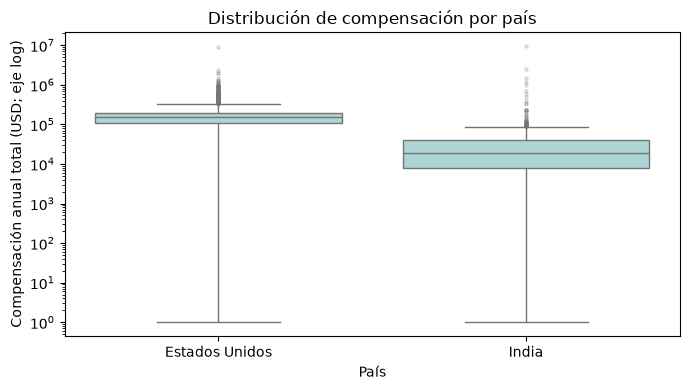

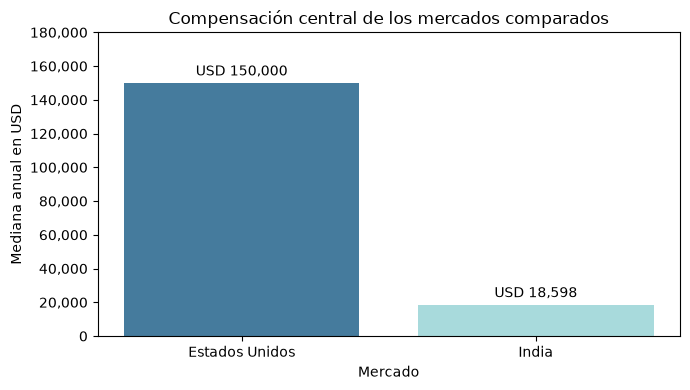

Lectura: la compensación mediana anual es USD 150,000 en Estados Unidos y USD 18,598 en India; el cociente es 8.07.
La diferencia observada y el contraste respaldan que la mediana estadounidense supera el doble de la india.
Experiencia, rol y tipo de empresa también pueden contribuir a esa diferencia; no aislamos un efecto del país ni del costo de vida.


In [ ]:
fig, ax = plt.subplots(figsize=(7, 4))
# Ordenamos los países para que la comparación coincida con el planteo.
sns.boxplot(data=df_paises, x="Country", y="ConvertedCompYearly", order=["United States of America", "India"], color="#a8dadc", flierprops={"markersize": 2, "alpha": 0.35}, ax=ax)
ax.set_yscale("log")
ax.set_xticks([0, 1], labels=["Estados Unidos", "India"])
ax.set_ylabel("Compensación anual total (USD; eje log)")
ax.set_xlabel("País")
ax.set_title("Distribución de compensación por país")
plt.tight_layout()
plt.show()


# Ordenamos las medianas igual que en el boxplot.
medianas_mercados = tabla_paises["mediana_USD"].reindex(["United States of America", "India"])
# Creamos una figura para leer las medidas centrales en USD sin escala logarítmica.
fig, ax = plt.subplots(figsize=(7, 4))
# Dibujamos una barra por mercado usando las medianas de la tabla.
barras_mediana_mercados = ax.bar(["Estados Unidos", "India"], medianas_mercados, color=["#457b9d", "#a8dadc"])
# Mostramos los importes para no depender de la lectura aproximada del eje.
ax.bar_label(barras_mediana_mercados, labels=[f"USD {valor:,.0f}" for valor in medianas_mercados], padding=3)
ax.set_ylim(0, medianas_mercados.max() * 1.2)
ax.set(title="Compensación central de los mercados comparados", xlabel="Mercado", ylabel="Mediana anual en USD")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.StrMethodFormatter("{x:,.0f}"))
plt.tight_layout()
plt.show()


apoyo_h2 = p_h2 < alpha and ratio_mediana > 2
print(f"Lectura: la compensación mediana anual es USD {sueldos_usa.median():,.0f} en Estados Unidos y USD {sueldos_india.median():,.0f} en India; el cociente es {ratio_mediana:.2f}.")
print("La diferencia observada y el contraste respaldan que la mediana estadounidense supera el doble de la india." if apoyo_h2 else "El resultado no alcanza para sostener la diferencia que habíamos propuesto.")
print("Experiencia, rol y tipo de empresa también pueden contribuir a esa diferencia; no aislamos un efecto del país ni del costo de vida.")

### 4.3. Perfil multivariado: 18–24 frente a 25 años o más

Usamos las mismas personas en las tres comparaciones: edad, experiencia, compensación y frecuencia de IA deben estar informadas.

| Componente | H₀ | H₁ / dirección esperada | Contraste |
|---|---|---|---|
| Experiencia | Medianas iguales entre grupos | Distintas; esperamos mayor en 25+ | Test de la mediana, bilateral |
| Compensación | Medianas iguales entre grupos | Distintas; esperamos mayor en 25+ | Test de la mediana, bilateral |
| Uso diario de IA | p_25+ ≥ p_18–24 | p_25+ < p_18–24 | Dos proporciones, unilateral |

Para las medianas exigimos diferencia significativa y la dirección propuesta; un resultado significativo en sentido contrario no apoyaría el planteo. Para el uso diario aplicamos la diferencia de proporciones estandarizada, con proporción agrupada bajo H₀, de la Clase 5, p. 23. La hipótesis del perfil requiere las tres condiciones.

Estos contrastes describen diferencias entre perfiles. No estiman el efecto de la edad manteniendo constantes país, rol o tipo de empresa, ni prueban resistencia al uso de IA.

**Por qué usamos tres paneles:** los boxplots permiten comparar las medianas y la dispersión de experiencia y compensación, y las barras comparan una proporción. Cada panel responde a una condición del perfil. Conservamos todos los salarios con eje logarítmico y usamos 0–100% para el uso diario, para no exagerar la diferencia (Práctica 5, pp. 5–7 y 14–18).

#### Detalle de los intervalos antes de agrupar

Primero mostramos los seis rangos de edad originales sobre los mismos casos completos que entran en el contraste. Esto permite ver la variación que resume el grupo de 25 o más. La tabla informa tamaños, medianas y cantidades de usuarios diarios; el porcentaje se calcula dentro de cada rango.

**Por qué barras por intervalo:** permiten comparar la frecuencia de uso diario sin asumir edades exactas dentro de los rangos. Mantenemos el orden de edad y una escala de 0 a 100%; las cantidades quedan indicadas para reconocer las diferencias de tamaño. Esta vista es descriptiva y no incorpora contrastes adicionales (Práctica 5, pp. 5–7).


Casos completos utilizados: 19434
                      n  experiencia_mediana  compensacion_mediana_USD  usuarios_IA_diaria  uso_diario_pct
Age                                                                                                       
18-24 years old    1835                  2.0                   27290.0                1051           57.28
25-34 years old    7312                  7.0                   65624.0                3906           53.42
35-44 years old    6325                 15.0                   92812.0                3291           52.03
45-54 years old    2729                 25.0                  104413.0                1326           48.59
55-64 years old    1036                 34.0                  110244.5                 374           36.10
65 years or older   197                 44.0                  110420.0                  66           33.50


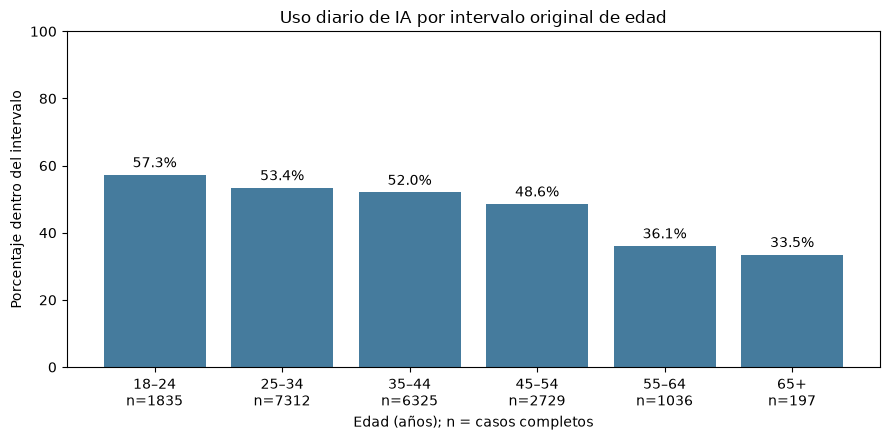

Casos de un siglo declarado dentro de esta hipótesis: 0
La comparación con y sin esos casos coincide porque ninguno participa en los casos completos de edad.


In [41]:
# Necesitamos las cuatro variables para comparar el mismo conjunto de personas.
columnas_multi = ["Age", "WorkExp", "ConvertedCompYearly", "AISelect"]
# Excluimos faltantes solo de este análisis, no del archivo limpio.
df_multi = datos_profesionales.dropna(subset=columnas_multi).copy()
# Definimos los intervalos de edad que forman cada uno de los dos grupos.
mapa_grupos_edad = {"18-24 years old": "18–24", "25-34 years old": "25 o más", "35-44 years old": "25 o más", "45-54 years old": "25 o más", "55-64 years old": "25 o más", "65 years or older": "25 o más"}
# Conservamos las categorías definidas y compensaciones positivas, sin recortar extremos.
df_multi = df_multi[df_multi["Age"].isin(mapa_grupos_edad) & (df_multi["ConvertedCompYearly"] > 0)].copy()
# Identificamos uso diario en esta misma vista de casos completos.
df_multi["Usa_IA_Diario"] = df_multi["AISelect"].eq("Yes, I use AI tools daily")
# Ordenamos los intervalos originales sin reemplazarlos por una edad puntual.
orden_edades = ["18-24 years old", "25-34 years old", "35-44 years old", "45-54 years old", "55-64 years old", "65 years or older"]
# Resumimos las cuatro variables sobre las mismas personas de cada intervalo.
tabla_intervalos_edad = df_multi.groupby("Age").agg(n=("ResponseId", "count"), experiencia_mediana=("WorkExp", "median"), compensacion_mediana_USD=("ConvertedCompYearly", "median"), usuarios_IA_diaria=("Usa_IA_Diario", "sum")).reindex(orden_edades)
# Obtenemos el porcentaje a partir de la cantidad de usuarios diarios y el tamaño del intervalo.
tabla_intervalos_edad["uso_diario_pct"] = tabla_intervalos_edad["usuarios_IA_diaria"] / tabla_intervalos_edad["n"] * 100
# Mostramos el total de casos que se mantiene para esta vista y la comparación posterior.
print("Casos completos utilizados:", len(df_multi))
# Presentamos las cantidades y medidas que alimentan el gráfico.
print(tabla_intervalos_edad.round(2).to_string())
# Creamos una figura para los seis intervalos de edad.
fig, ax = plt.subplots(figsize=(9, 4.5))
# Usamos etiquetas breves para los mismos intervalos del cuestionario.
etiquetas_edades = ["18–24", "25–34", "35–44", "45–54", "55–64", "65+"]
# Dibujamos los porcentajes calculados sin truncar el eje vertical.
barras_edad = ax.bar(etiquetas_edades, tabla_intervalos_edad["uso_diario_pct"], color="#457b9d")
# Indicamos el porcentaje observado encima de cada barra.
ax.bar_label(barras_edad, labels=[f"{valor:.1f}%" for valor in tabla_intervalos_edad["uso_diario_pct"]], padding=3)
# Añadimos el tamaño de cada intervalo debajo de su etiqueta.
ax.set_xticks(range(len(etiquetas_edades)), labels=[f"{etiqueta}\nn={int(cantidad)}" for etiqueta, cantidad in zip(etiquetas_edades, tabla_intervalos_edad["n"])])
# Conservamos el recorrido completo de porcentajes.
ax.set_ylim(0, 100)
# Indicamos la población y las variables representadas.
ax.set(title="Uso diario de IA por intervalo original de edad", xlabel="Edad (años); n = casos completos", ylabel="Porcentaje dentro del intervalo")
# Ajustamos los márgenes para que entren porcentajes y tamaños.
plt.tight_layout()
# Mostramos el gráfico construido con la tabla de los seis intervalos.
plt.show()


# Comprobamos cuántos casos señalados con un siglo declarado entran realmente en esta muestra.
casos_siglo_en_edad = df_multi[df_multi["ResponseId"].isin(ids_exp_dudosa)]
# Mostramos el resultado antes de considerar una comparación con y sin esos casos.
print("Casos de un siglo declarado dentro de esta hipótesis:", len(casos_siglo_en_edad))
# Si el resultado es cero, quitar esos casos no cambia las tablas ni los gráficos anteriores.
print("La comparación con y sin esos casos coincide porque ninguno participa en los casos completos de edad." if casos_siglo_en_edad.empty else "Hay casos señalados: corresponde revisar su influencia en esta hipótesis.")


Con este detalle a la vista, reunimos los intervalos de 25 años o más para la comparación definida en la hipótesis. Las tres condiciones se contrastan sobre los mismos casos completos. La agrupación no implica que los distintos rangos tengan comportamientos idénticos ni permite interpretar las diferencias como una evolución individual.


El control de participación anterior distingue los extremos presentes en la base de los que efectivamente entran en esta hipótesis. No reintroducimos valores incompatibles ya corregidos para construir una comparación artificial.


In [42]:
# Agrupamos edades sin inventar una edad exacta dentro de cada intervalo.
df_multi["Grupo_edad"] = df_multi["Age"].map(mapa_grupos_edad)
# Establecemos el orden de referencia de las tablas y gráficos.
orden_grupos = ["18–24", "25 o más"]
# Calculamos tamaños, medianas y proporción de uso diario sobre los mismos casos.
tabla_multi = df_multi.groupby("Grupo_edad").agg(n=("ResponseId", "count"), experiencia_mediana=("WorkExp", "median"), compensacion_mediana_USD=("ConvertedCompYearly", "median"), usuarios_IA_diaria=("Usa_IA_Diario", "sum"), uso_diario_pct=("Usa_IA_Diario", lambda x: x.mean() * 100)).reindex(orden_grupos)
# Mostramos el tamaño efectivo y las características que contrastaremos.
print("Casos completos:", len(df_multi), "| Fuera del análisis:", len(datos_profesionales) - len(df_multi))
# Imprimimos una fila por perfil para mantener breve la comparación.
print(tabla_multi.round(2).to_string())

Casos completos: 19434 | Fuera del análisis: 17462
                n  experiencia_mediana  compensacion_mediana_USD  usuarios_IA_diaria  uso_diario_pct
Grupo_edad                                                                                          
18–24        1835                  2.0                   27290.0                1051           57.28
25 o más    17599                 12.0                   83531.0                8963           50.93


In [43]:
# Separamos las personas del grupo de referencia.
jovenes = df_multi[df_multi["Grupo_edad"].eq("18–24")]
# Separamos las personas de 25 años o más.
mayores = df_multi[df_multi["Grupo_edad"].eq("25 o más")]
# Contrastamos las medianas de experiencia sin suponer normalidad.
resultado_multi_exp = stats.median_test(jovenes["WorkExp"], mayores["WorkExp"], ties="below", correction=True)
# Contrastamos las medianas de compensación manteniendo los extremos en los datos.
resultado_multi_comp = stats.median_test(jovenes["ConvertedCompYearly"], mayores["ConvertedCompYearly"], ties="below", correction=True)
# Revisamos las frecuencias esperadas de ambos contrastes de medianas.
for resultado_mediana in [resultado_multi_exp, resultado_multi_comp]:
    esperadas = stats.chi2_contingency(resultado_mediana.table).expected_freq  # Recuperamos los conteos esperados bajo H₀.
    if esperadas.min() < 5:
        raise ValueError("Hay frecuencias esperadas insuficientes para el test de la mediana.")  # Evitamos una interpretación automática fuera de sus condiciones.
# Contamos los usuarios diarios de cada grupo.
k_mayores, k_jovenes = mayores["Usa_IA_Diario"].sum(), jovenes["Usa_IA_Diario"].sum()
# Guardamos los denominadores de las dos proporciones.
n_mayores, n_jovenes = len(mayores), len(jovenes)
# Calculamos las proporciones de uso diario observadas.
prop_mayores, prop_jovenes = k_mayores / n_mayores, k_jovenes / n_jovenes
# Bajo la igualdad del límite de H₀, estimamos una proporción común.
prop_agrupada = (k_mayores + k_jovenes) / (n_mayores + n_jovenes)
# Verificamos los éxitos y fracasos esperados de los dos grupos.
minimo_esperado_multi = min(n_mayores * prop_agrupada, n_mayores * (1 - prop_agrupada), n_jovenes * prop_agrupada, n_jovenes * (1 - prop_agrupada))
# La aproximación normal no se interpreta si los conteos esperados son pequeños.
if minimo_esperado_multi < 5:
    raise ValueError("Faltan casos para comparar las proporciones mediante aproximación normal.")  # Mantenemos explícita la condición del test.
# Calculamos el error estándar de la diferencia bajo H₀.
error_prop = np.sqrt(prop_agrupada * (1 - prop_agrupada) * (1 / n_mayores + 1 / n_jovenes))
# Estandarizamos la proporción de mayores menos la de jóvenes.
z_multi_ia = (prop_mayores - prop_jovenes) / error_prop
# La cola izquierda corresponde a un menor uso diario en 25+.
p_multi_ia = stats.norm.cdf(z_multi_ia)
# Guardamos los resultados completos para decidir, aunque la tabla muestre p abreviado.
p_multi_exp, p_multi_comp = resultado_multi_exp.pvalue, resultado_multi_comp.pvalue
# Comprobamos que las medianas observadas estén en la dirección de la hipótesis.
direccion_exp = mayores["WorkExp"].median() > jovenes["WorkExp"].median()
# Revisamos por separado la dirección salarial.
direccion_comp = mayores["ConvertedCompYearly"].median() > jovenes["ConvertedCompYearly"].median()
# Reunimos las tres condiciones sin mezclar una mediana con una proporción.
resultados_multi = pd.DataFrame({"Componente": ["Experiencia", "Compensación", "Uso diario de IA"], "Test": ["Mediana", "Mediana", "Dos proporciones"], "Estadístico": [resultado_multi_exp.statistic, resultado_multi_comp.statistic, z_multi_ia], "p": [mostrar_p(p_multi_exp), mostrar_p(p_multi_comp), mostrar_p(p_multi_ia)], "Dirección esperada": [direccion_exp, direccion_comp, prop_mayores < prop_jovenes]})
# Mostramos únicamente los contrastes planificados.
print(resultados_multi.round(2).to_string(index=False))
# Exigimos evidencia en las tres condiciones y no solo en una característica del perfil.
apoyo_multi = p_multi_exp < alpha and p_multi_comp < alpha and p_multi_ia < alpha and direccion_exp and direccion_comp and prop_mayores < prop_jovenes
# Comunicamos el alcance del resultado, sin atribuir las diferencias a una causa.
print("Las tres condiciones tienen apoyo en estos datos." if apoyo_multi else "No hay apoyo suficiente para las tres condiciones del perfil.")

      Componente             Test  Estadístico      p  Dirección esperada
     Experiencia          Mediana      1853.96 <0,001                True
    Compensación          Mediana      1136.27 <0,001                True
Uso diario de IA Dos proporciones        -5.18 <0,001                True
Las tres condiciones tienen apoyo en estos datos.


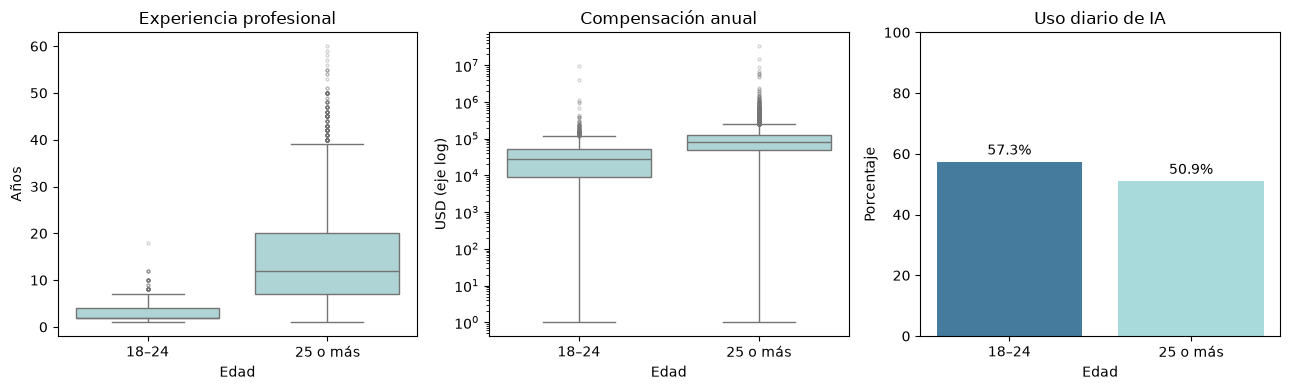

Lectura: 25+ presenta 12 años de experiencia mediana y USD 83,531 anuales, frente a 2 años y USD 27,290 en 18–24.
El uso diario es 50.93% en 25+ y 57.28% en 18–24: una diferencia de 6.35 puntos porcentuales.
Los tres contrastes respaldan el perfil definido.
Estos grupos pueden diferir también en país y rol. El resultado no describe una evolución individual ni mide resistencia a la IA.


In [44]:
# Organizamos un panel por componente para que la figura siga la hipótesis.
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
# Mostramos la distribución completa de experiencia por grupo.
sns.boxplot(data=df_multi, x="Grupo_edad", y="WorkExp", order=orden_grupos, color="#a8dadc", flierprops={"markersize": 2, "alpha": 0.3}, ax=axes[0])
# Rotulamos el componente de experiencia.
axes[0].set(title="Experiencia profesional", xlabel="Edad", ylabel="Años")
# Mostramos todas las compensaciones, sin filtros solo para el dibujo.
sns.boxplot(data=df_multi, x="Grupo_edad", y="ConvertedCompYearly", order=orden_grupos, color="#a8dadc", flierprops={"markersize": 2, "alpha": 0.3}, ax=axes[1])
# La escala logarítmica permite representar valores muy diferentes sin recortarlos.
axes[1].set_yscale("log")
# Dejamos indicada la unidad anual y la escala.
axes[1].set(title="Compensación anual", xlabel="Edad", ylabel="USD (eje log)")
# Dibujamos las proporciones calculadas sobre los mismos casos completos.
barras_multi = axes[2].bar(orden_grupos, tabla_multi["uso_diario_pct"], color=["#457b9d", "#a8dadc"])
# Indicamos los porcentajes para ver la magnitud de la diferencia.
axes[2].bar_label(barras_multi, labels=[f"{valor:.1f}%" for valor in tabla_multi["uso_diario_pct"]], padding=3)
# Usamos una escala completa de porcentajes para no exagerar la diferencia.
axes[2].set_ylim(0, 100)
# Rotulamos el componente de uso de IA.
axes[2].set(title="Uso diario de IA", xlabel="Edad", ylabel="Porcentaje")
# Ajustamos los espacios entre los tres paneles.
plt.tight_layout()
# Mostramos la figura conjunta del perfil.
plt.show()

# Recuperamos los dos perfiles de la tabla que alimentó los gráficos y los contrastes.
perfil_joven = tabla_multi.loc["18–24"]
# Conservamos el grupo de comparación con los mismos casos completos.
perfil_mayor = tabla_multi.loc["25 o más"]
# Cuantificamos la diferencia de uso diario en puntos porcentuales, no como cambio relativo.
diferencia_ia_pp = perfil_joven["uso_diario_pct"] - perfil_mayor["uso_diario_pct"]
# Interpretamos los dos componentes de magnitud sobre las medianas calculadas.
print(f"Lectura: 25+ presenta {perfil_mayor['experiencia_mediana']:.0f} años de experiencia mediana y USD {perfil_mayor['compensacion_mediana_USD']:,.0f} anuales, frente a {perfil_joven['experiencia_mediana']:.0f} años y USD {perfil_joven['compensacion_mediana_USD']:,.0f} en 18–24.")
# Expresamos la frecuencia de IA con los mismos denominadores de la tabla.
print(f"El uso diario es {perfil_mayor['uso_diario_pct']:.2f}% en 25+ y {perfil_joven['uso_diario_pct']:.2f}% en 18–24: una diferencia de {diferencia_ia_pp:.2f} puntos porcentuales.")
# Interpretamos conjuntamente las tres condiciones sin ampliar el alcance a cada rango de edad original.
print("Los tres contrastes respaldan el perfil definido." if apoyo_multi else "No encontramos apoyo para las tres condiciones del perfil definido.")
# Evitamos interpretar una comparación de grupos como el cambio de una misma persona al envejecer.
print("Estos grupos pueden diferir también en país y rol. El resultado no describe una evolución individual ni mide resistencia a la IA.")

### 4.4. Hipótesis A: mediana de compensación en Argentina y tres SMVM

Usamos la **mediana** para representar la compensación central. Estudiamos profesionales de Argentina con compensación anual informada y positiva, conservando todos los valores que cumplen esas condiciones. Interpretamos la hipótesis como **superar el umbral de tres SMVM**, no como demostrar una igualdad exacta.

Conservamos la referencia del grupo: SMVM mensual de **ARS 391.200**, 12 meses y **ARS 1.570 por USD**. Comparamos compensaciones declaradas en la encuesta 2025 con SMVM de octubre de 2026; es un escenario de referencia, no una comparación del poder adquisitivo en el mismo período. La cotización es un supuesto del grupo.

**H₀:** mediana_Argentina ≤ tres SMVM anuales en USD. **H₁:** mediana_Argentina > ese umbral.

Usamos una **prueba del signo**, expresada como contraste de una proporción con p₀ = 0,5. Calculamos compensación − umbral y contamos cuántos signos son positivos y negativos. Los empates no aportan signo. Con suficientes casos, aproximamos mediante z y la cola derecha. No requiere normalidad salarial ni simetría de las diferencias. Aquí no hay empates con el umbral; la hipótesis de una mediana superior se expresa como más de la mitad de las compensaciones por encima de él.

El SMVM es una referencia fija, no una segunda muestra de personas. Por eso no armamos un grupo artificial de valores iguales al SMVM para aplicar una comparación entre dos muestras.

**Por qué un boxplot con referencia:** representa la mediana solicitada, el 50% central y la dispersión; la línea de tres SMVM permite comparar directamente ambas magnitudes. Mostramos además los conteos del test, porque el gráfico no sustituye su cálculo (Práctica 5, pp. 14–18).

Referencia estadística: prueba del signo en Clase 5, pp. 25, 36 y 51; contraste de una proporción en p. 4 y estandarización de proporciones en p. 23. La aplicación a compensación − umbral es nuestra adaptación a esta hipótesis.

**Por qué agregamos barras de cantidades:** el boxplot compara la compensación central con el umbral; las barras muestran cuántos signos positivos, negativos o empates alimentan la prueba. Así se puede relacionar el test con sus observaciones de origen (Práctica 5, pp. 5–7).


In [45]:
# Conservamos el SMVM mensual elegido por el grupo.
smvm_mensual_ars = 391200
# Lo expresamos en doce meses para compararlo con una compensación anual.
smvm_anual_ars = smvm_mensual_ars * 12
# Conservamos el tipo de cambio de referencia de las versiones anteriores.
tipo_cambio_usd = 1570
# Convertimos el SMVM anual a USD.
smvm_anual_usd = smvm_anual_ars / tipo_cambio_usd
# Calculamos el umbral de tres SMVM anuales, que queda fijo para el contraste.
umbral_3_smvm_usd = 3 * smvm_anual_usd
# Filtramos profesionales de Argentina con compensación informada.
df_arg = datos_profesionales[datos_profesionales["Country"].eq("Argentina")].dropna(subset=["ConvertedCompYearly"]).copy()
# Conservamos los valores positivos sin retirar extremos por su magnitud.
sueldos_arg = df_arg.loc[df_arg["ConvertedCompYearly"] > 0, "ConvertedCompYearly"]
# Calculamos el tamaño efectivo y la mediana que pide la hipótesis.
n_arg, mediana_arg = len(sueldos_arg), sueldos_arg.median()
# Mostramos las medidas que se compararán, en la misma unidad anual.
print(f"Compensaciones válidas: {n_arg} | Mediana anual: USD {mediana_arg:,.2f} | Tres SMVM del escenario: USD {umbral_3_smvm_usd:,.2f}")


Compensaciones válidas: 136 | Mediana anual: USD 40,473.50 | Tres SMVM del escenario: USD 8,970.19


#### Revisión de los importes más bajos

Ordenamos las compensaciones de Argentina para mostrar los cinco valores menores con su moneda y monto de origen. También calculamos una vista auxiliar sin el mínimo para comprobar su influencia sobre la mediana, sin retirarlo del análisis principal.


In [46]:
# Conservamos la misma selección de compensaciones positivas de Argentina.
datos_argentina = df_arg[df_arg["ConvertedCompYearly"] > 0].copy()
# Detectamos los cinco importes menores mediante ordenamiento y resolvemos empates por el ID.
compensaciones_bajas_arg = datos_argentina.sort_values(["ConvertedCompYearly", "ResponseId"]).head(5)
# Recuperamos el mínimo como ejemplo reproducible, sin escribir su identificador a mano.
ejemplo_argentina = compensaciones_bajas_arg.head(1)
# Mostramos el monto y la moneda que permiten interpretar cada conversión.
print(compensaciones_bajas_arg[["ResponseId", "Currency", "CompTotal", "ConvertedCompYearly"]].to_string(index=False))
# Quitamos el mínimo solo de una vista auxiliar para comprobar su influencia.
arg_sin_minimo = sueldos_arg.drop(sueldos_arg.idxmin())
# Reunimos el tamaño y la mediana de ambos escenarios descriptivos.
control_minimo_arg = pd.DataFrame({"n": [n_arg, len(arg_sin_minimo)], "Mediana anual USD": [mediana_arg, arg_sin_minimo.median()]}, index=["Análisis principal", "Control sin el mínimo"])
# Dejamos visible la comparación que sustenta la interpretación posterior.
print(control_minimo_arg.round(2).to_string())


 ResponseId                 Currency  CompTotal  ConvertedCompYearly
      25964      ARS\tArgentine peso    12000.0                 10.0
      17848      ARS\tArgentine peso    14000.0                 12.0
      23275      ARS\tArgentine peso    15000.0                 13.0
      32102      ARS\tArgentine peso    24000.0                 20.0
      41804 USD United States dollar       26.0                 26.0
                         n  Mediana anual USD
Análisis principal     136            40473.5
Control sin el mínimo  135            40947.0


La tabla muestra montos declarados en pesos que resultan muy bajos al expresarse en USD. No sabemos si se confundieron las unidades o el período del importe, por lo que no reconstruimos otro salario. Conservamos esos datos con esa limitación.

El control permite ver cuánto cambia la mediana al retirar únicamente el mínimo. Es una comprobación auxiliar, no una decisión de limpieza ni una justificación para excluir respuestas que queden por debajo del SMVM. El contraste principal mantiene todas las compensaciones seleccionadas.


In [47]:
# Restamos la referencia a cada respuesta para obtener los signos del contraste.
diferencias_smvm = sueldos_arg - umbral_3_smvm_usd
# Contamos las compensaciones superiores al umbral.
por_encima_smvm = int((diferencias_smvm > 0).sum())
# Contamos las compensaciones inferiores al umbral.
por_debajo_smvm = int((diferencias_smvm < 0).sum())
# Identificamos los empates para no tratarlos como signos positivos ni negativos.
empates_smvm = int((diferencias_smvm == 0).sum())
# El tamaño del test del signo excluye los empates.
n_signos = por_encima_smvm + por_debajo_smvm
# Mostramos los conteos exactos que alimentan el contraste.
tabla_signos_smvm = pd.DataFrame({"Cantidad": [por_debajo_smvm, empates_smvm, por_encima_smvm]}, index=["Debajo del umbral", "Igual al umbral", "Encima del umbral"])
# Dejamos visibles numerador y denominador antes de mostrar el p-valor.
print(tabla_signos_smvm.to_string())
# Comprobamos éxitos y fracasos esperados bajo p₀ = 0,5 para la aproximación normal.
if n_signos * 0.5 < 5:
    raise ValueError("No hay suficientes signos para la aproximación normal.")  # Evitamos interpretar un método fuera de sus condiciones.
# Calculamos la proporción de signos positivos entre los no empatados.
proporcion_encima_smvm = por_encima_smvm / n_signos
# Estandarizamos la proporción respecto de 0,5, igual que en los otros contrastes de una proporción.
z_a = (proporcion_encima_smvm - 0.5) / np.sqrt(0.5 * (1 - 0.5) / n_signos)
# La cola derecha responde a una mediana superior al umbral.
p_a = stats.norm.sf(z_a)
# Informamos el tamaño y la comparación de medianas en USD anuales.
print(f"n = {n_arg}; mediana anual = USD {mediana_arg:,.2f}; tres SMVM = USD {umbral_3_smvm_usd:,.2f}.")
# Mostramos el resultado del test y la proporción observada que lo origina.
print(f"Signos positivos: {por_encima_smvm}/{n_signos} ({100 * proporcion_encima_smvm:.2f}%); z = {z_a:.2f}; p {mostrar_p(p_a)}.")
# Interpretamos el contraste dentro del escenario económico declarado.
print("Se rechaza H₀: hay evidencia de que la mediana supera tres SMVM en el escenario elegido." if p_a < alpha else "No hay evidencia suficiente de que la mediana supere tres SMVM.")
# Retiramos el máximo solo de una vista auxiliar para revisar su influencia.
arg_sin_maximo = sueldos_arg.drop(sueldos_arg.idxmax())
# Recalculamos los signos de esa vista manteniendo la referencia original.
signos_sensibilidad = arg_sin_maximo - umbral_3_smvm_usd
# Contamos los signos no nulos y los positivos de la comprobación.
n_signos_sensibilidad, positivos_sensibilidad = int((signos_sensibilidad != 0).sum()), int((signos_sensibilidad > 0).sum())
# Aplicamos el mismo estadístico normal, sin elegir un nuevo contraste por su resultado.
z_a_sensibilidad = (positivos_sensibilidad / n_signos_sensibilidad - 0.5) / np.sqrt(0.25 / n_signos_sensibilidad)
# Obtenemos el p-valor de la misma alternativa de mediana superior.
p_a_sensibilidad = stats.norm.sf(z_a_sensibilidad)
# Mostramos el control sin borrar ese máximo del análisis principal.
print(f"Control sin el máximo: mediana USD {arg_sin_maximo.median():,.2f}; p {mostrar_p(p_a_sensibilidad)}. El análisis principal conserva ese caso.")

                   Cantidad
Debajo del umbral        22
Igual al umbral           0
Encima del umbral       114
n = 136; mediana anual = USD 40,473.50; tres SMVM = USD 8,970.19.
Signos positivos: 114/136 (83.82%); z = 7.89; p <0,001.
Se rechaza H₀: hay evidencia de que la mediana supera tres SMVM en el escenario elegido.
Control sin el máximo: mediana USD 40,000.00; p <0,001. El análisis principal conserva ese caso.


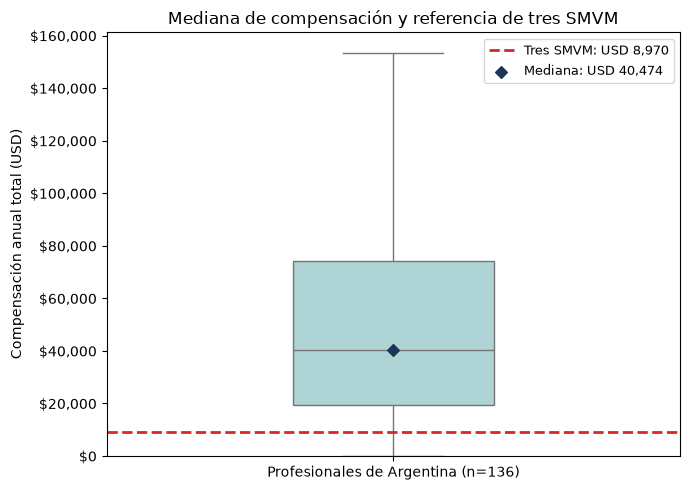

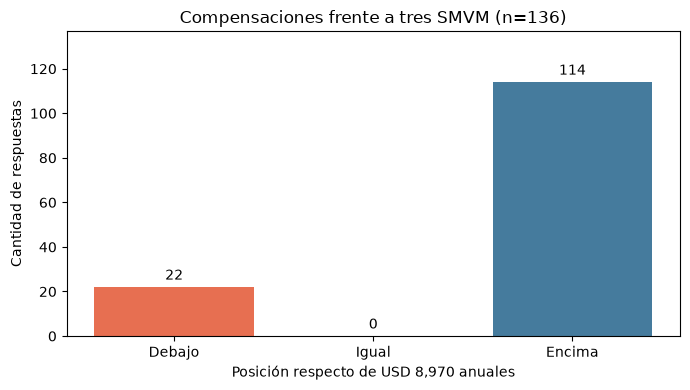

Lectura: la mediana anual de USD 40,473.50 está por encima de la referencia de USD 8,970.19; 114 de las 136 compensaciones superan ese umbral.
La prueba del signo respalda una mediana superior a tres SMVM en el escenario fijado.
El SMVM y la cotización son las referencias elegidas por el grupo; esta comparación mezcla períodos y no mide poder adquisitivo en un mismo momento.


In [48]:
# Creamos una figura para comparar la mediana salarial y el umbral de referencia.
fig, ax = plt.subplots(figsize=(7, 5))
# El boxplot usa todas las compensaciones del contraste y conserva visibles los extremos.
sns.boxplot(y=sueldos_arg, color="#a8dadc", width=0.35, ax=ax)
# Dejamos margen lateral para que una sola caja no ocupe todo el ancho de la figura.
ax.set_xlim(-0.5, 0.5)
# Comenzamos en cero porque todas las compensaciones representadas son positivas.
ax.set_ylim(bottom=0)
# Marcamos la referencia fija de tres SMVM anuales.
ax.axhline(umbral_3_smvm_usd, color="#d62828", linestyle="--", linewidth=2, label=f"Tres SMVM: USD {umbral_3_smvm_usd:,.0f}")
# Destacamos la mediana calculada, que ya aparece como línea dentro de la caja.
ax.scatter([0], [mediana_arg], color="#1d3557", marker="D", zorder=3, label=f"Mediana: USD {mediana_arg:,.0f}")
# Usamos una etiqueta de población en lugar de una posición numérica del gráfico.
ax.set_xticks([0], labels=[f"Profesionales de Argentina (n={n_arg})"])
# Indicamos que se trata de compensación anual total en USD.
ax.set(title="Mediana de compensación y referencia de tres SMVM", ylabel="Compensación anual total (USD)", xlabel="")
# Formateamos las magnitudes sin notación científica.
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.StrMethodFormatter("${x:,.0f}"))
# Identificamos el umbral y la mediana en la leyenda.
ax.legend(fontsize=9)
# Ajustamos los márgenes de la figura.
plt.tight_layout()
# Mostramos el gráfico, cuyo dato de origen es sueldos_arg.
plt.show()


# Dibujamos directamente los conteos que utiliza la prueba del signo.
fig, ax = plt.subplots(figsize=(7, 4))
# Cada barra corresponde a una relación de la compensación con el umbral fijo.
barras_signos = ax.bar(["Debajo", "Igual", "Encima"], tabla_signos_smvm["Cantidad"], color=["#e76f51", "#adb5bd", "#457b9d"])
# Informamos las cantidades exactas encima de las barras.
ax.bar_label(barras_signos, labels=[str(int(valor)) for valor in tabla_signos_smvm["Cantidad"]], padding=3)
# Dejamos margen para que se lean los conteos.
ax.set_ylim(0, tabla_signos_smvm["Cantidad"].max() * 1.2)
# Identificamos el umbral y el total de personas de esta comparación.
ax.set(title=f"Compensaciones frente a tres SMVM (n={n_arg})", xlabel=f"Posición respecto de USD {umbral_3_smvm_usd:,.0f} anuales", ylabel="Cantidad de respuestas")
# Ajustamos los márgenes y mostramos el gráfico de los signos.
plt.tight_layout()
plt.show()

# Guardamos el apoyo al planteo con la mediana y el test del signo ya calculados.
apoyo_a = p_a < alpha and mediana_arg > umbral_3_smvm_usd
# Explicamos el resultado a partir de su mediana, referencia y conteo de signos.
print(f"Lectura: la mediana anual de USD {mediana_arg:,.2f} está por encima de la referencia de USD {umbral_3_smvm_usd:,.2f}; {por_encima_smvm} de las {n_arg} compensaciones superan ese umbral.")
# La conclusión se refiere a la mediana, no a todas las personas ni a una igualdad exacta con tres SMVM.
print("La prueba del signo respalda una mediana superior a tres SMVM en el escenario fijado." if apoyo_a else "La prueba del signo no aporta evidencia suficiente de una mediana superior al umbral.")
# Recordamos la principal limitación económica de esa comparación.
print("El SMVM y la cotización son las referencias elegidas por el grupo; esta comparación mezcla períodos y no mide poder adquisitivo en un mismo momento.")

### 4.5. Hipótesis B: experiencia profesional y confianza en la IA

La confianza tiene cinco categorías ordenadas. Comparamos la experiencia entre esas categorías para estudiar su asociación; eso no demuestra que la experiencia cause una respuesta de confianza.

Revisamos **Shapiro-Wilk** en cada grupo y **Levene** para la igualdad de varianzas, como preparación para decidir si un ANOVA clásico sería razonable. Para Shapiro usamos hasta 5.000 casos por grupo, con semilla fija: su p-valor pierde precisión para n mayores. Esta submuestra se usa solo en el diagnóstico; el contraste principal usa todos los casos disponibles.

Las distribuciones de experiencia son asimétricas y las varianzas no son homogéneas. Por eso elegimos **Kruskal-Wallis**, alternativa no paramétrica al ANOVA para varios grupos independientes.

**H₀:** la distribución de experiencia es la misma en los cinco grupos. **H₁:** al menos una difiere. Sin asumir formas similares, no interpretamos el rechazo como una prueba exclusiva de diferencias de medianas ni como que todos los pares difieren.

Complementamos con **Spearman** para describir dirección e intensidad de la asociación entre experiencia y confianza ordenada. Para ese contraste, H₀ es ρ_s = 0 y H₁ es ρ_s ≠ 0. Un p pequeño puede coexistir con una relación muy débil.

Referencias: Clase 5, pp. 15–18, 24–25 y 37–49; Clase 3, pp. 19–23. El límite diagnóstico de Shapiro también se advierte en la Práctica 9, p. 19, y en la documentación de SciPy.

**Por qué boxplots horizontales comparativos:** mostramos los grupos con todos los casos y sin los registros señalados, usando el mismo eje de años. Así se puede observar la influencia del extremo sin exagerarla mediante un cambio de escala. Agregamos barras de medianas para leer los valores centrales exactos; esas barras no reemplazan la comparación de distribuciones ni convierten una asociación débil en una relación fuerte (Práctica 5, pp. 5–7 y 14–18).

#### Casos señalados que participan en esta comparación

Retomamos los identificadores detectados durante la limpieza y verificamos cuáles tienen experiencia y confianza informadas dentro del grupo profesional. La tabla siguiente identifica el caso que se retira únicamente en la comprobación auxiliar.


In [49]:
# Seleccionamos los casos señalados que cumplen las condiciones de esta hipótesis.
candidatos_experiencia = casos_exp_dudosa[casos_exp_dudosa["MainBranch"].eq(perfil_profesional)].dropna(subset=["WorkExp", "AIAcc"])
# Ordenamos los identificadores para recuperar un ejemplo de forma reproducible.
ejemplo_experiencia = candidatos_experiencia.sort_values("ResponseId").head(1)
# Indicamos cuántos registros señalados entran en la comparación.
print("Casos señalados que participan en experiencia y confianza:", len(candidatos_experiencia))
# Mostramos los años declarados y la edad disponible antes de interpretar el caso.
print(candidatos_experiencia[["ResponseId", "Age", "WorkExp", "YearsCode", "AIAcc"]].to_string(index=False))
# Conservamos reunidos los ejemplos ya detectados, para poder consultar sus otras respuestas.
ejemplos_revision = pd.concat([ejemplo_india, ejemplo_usa, ejemplo_argentina, ejemplo_herramientas, ejemplo_experiencia])


Casos señalados que participan en experiencia y confianza: 1
 ResponseId Age  WorkExp  YearsCode           AIAcc
      43260 NaN     99.0      100.0 Highly distrust


In [50]:
# Conservamos las dos respuestas necesarias para comparar experiencia y confianza.
df_exp_ia = datos_profesionales.dropna(subset=["WorkExp", "AIAcc"]).copy()
# Separamos las experiencias por categoría, respetando el orden de confianza.
grupos_b = [df_exp_ia.loc[df_exp_ia["AIAcc"].eq(nivel), "WorkExp"] for nivel in orden_likert]
# Guardaremos los p-valores de normalidad por grupo.
p_shapiro_b = []
# Revisamos cada distribución, no la mezcla de los cinco grupos.
for valores in grupos_b:
    muestra_normalidad = valores.sample(n=min(5000, len(valores)), random_state=42)  # Limitamos solo el diagnóstico, de forma reproducible.
    p_shapiro_b.append(stats.shapiro(muestra_normalidad).pvalue)  # H₀ de Shapiro: la distribución es normal.
# Levene compara las varianzas usando todos los datos de los cinco grupos.
resultado_levene_b = stats.levene(*grupos_b, center="median")
# Resumimos tamaño y mediana para describir las diferencias observadas.
tabla_b = df_exp_ia.groupby("AIAcc")["WorkExp"].agg(n="count", mediana_años="median").reindex(orden_likert)
# Añadimos la evidencia del diagnóstico en la misma tabla para no duplicar salidas.
tabla_b["p Shapiro"] = [mostrar_p(valor) for valor in p_shapiro_b]
# Mostramos los cinco grupos y aclaramos el tamaño máximo del diagnóstico.
print("Shapiro: hasta 5.000 casos por grupo; los demás cálculos usan todos los disponibles.")
# Imprimimos una sola tabla breve.
print(tabla_b.to_string())
# Informamos el contraste de homogeneidad de varianzas.
print(f"Levene: W = {resultado_levene_b.statistic:.2f}; p {mostrar_p(resultado_levene_b.pvalue)}.")
# Guardamos si los diagnósticos darían apoyo a los supuestos clásicos del ANOVA.
anova_clasico_compatible = all(valor >= alpha for valor in p_shapiro_b) and resultado_levene_b.pvalue >= alpha
# Indicamos por qué usamos la alternativa por rangos en esta base.
print("Los diagnósticos no respaldan los supuestos del ANOVA clásico; usamos Kruskal-Wallis." if not anova_clasico_compatible else "Los diagnósticos no rechazan los supuestos; revisar también los gráficos antes de elegir ANOVA.")
# Ejecutamos el contraste global por rangos, sin hacer diez comparaciones de pares.
resultado_b = stats.kruskal(*grupos_b)
# Guardamos el p-valor del contraste principal.
p_b = resultado_b.pvalue
# Calculamos la asociación por rangos entre experiencia y confianza ordinal.
resultado_spearman_b = stats.spearmanr(df_exp_ia["WorkExp"], df_exp_ia["aiacc_ordinal"])
# Mostramos el resultado global y la magnitud de la tendencia.
print(f"Kruskal-Wallis: H = {resultado_b.statistic:.2f}; p {mostrar_p(p_b)}; Spearman ρ = {resultado_spearman_b.statistic:.3f}, p {mostrar_p(resultado_spearman_b.pvalue)}.")
# Interpretamos la evidencia sin confundir asociación con influencia causal.
print("Hay diferencias entre los grupos de confianza; no implica diferencias en todos los pares." if p_b < alpha else "No hay evidencia suficiente de diferencias entre los grupos.")
# Separamos una vista auxiliar sin los registros de experiencia señalados en la limpieza.
b_sensibilidad = df_exp_ia[~df_exp_ia["ResponseId"].isin(ids_exp_dudosa)].copy()
# Repetimos el mismo test en los grupos auxiliares.
resultado_b_sensibilidad = stats.kruskal(*[b_sensibilidad.loc[b_sensibilidad["AIAcc"].eq(nivel), "WorkExp"] for nivel in orden_likert])
# Mostramos si los casos de experiencia dudosa son los que determinan el resultado.
print(f"Sensibilidad sin {len(df_exp_ia) - len(b_sensibilidad)} caso(s) señalado(s): p {mostrar_p(resultado_b_sensibilidad.pvalue)}.")

Shapiro: hasta 5.000 casos por grupo; los demás cálculos usan todos los disponibles.
                               n  mediana_años p Shapiro
AIAcc                                                   
Highly distrust             4933          12.0    <0,001
Somewhat distrust           6617          11.0    <0,001
Neither trust nor distrust  5450          11.0    <0,001
Somewhat trust              7444          10.0    <0,001
Highly trust                 676          10.0    <0,001
Levene: W = 5.48; p <0,001.
Los diagnósticos no respaldan los supuestos del ANOVA clásico; usamos Kruskal-Wallis.
Kruskal-Wallis: H = 44.93; p <0,001; Spearman ρ = -0.041, p <0,001.
Hay diferencias entre los grupos de confianza; no implica diferencias en todos los pares.
Sensibilidad sin 1 caso(s) señalado(s): p <0,001.


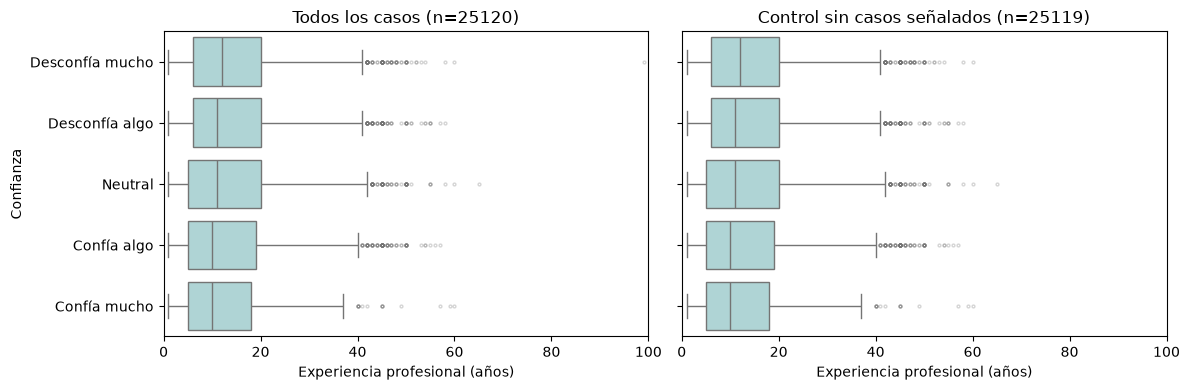

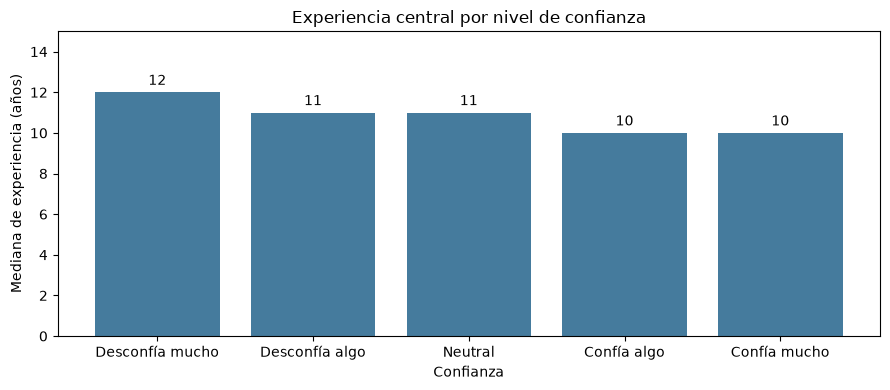

Lectura: las medianas de experiencia son 12 años en quienes desconfían mucho y 10 en quienes confían mucho.
Spearman da ρ = -0.041: la tendencia observada es inversa y muy débil, aunque resulte significativa.
Las diferencias globales no permiten afirmar que la experiencia determine la confianza ni identificar por sí solas todos los pares distintos.


In [51]:
# Organizamos una comparación con y sin los registros señalados.
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True, sharey=True)
# Conservamos las dos vistas sin modificar el análisis principal.
vistas_experiencia = [(df_exp_ia, "Todos los casos"), (b_sensibilidad, "Control sin casos señalados")]
# Dibujamos los mismos grupos de confianza en ambos paneles.
for ax, (vista, titulo) in zip(axes, vistas_experiencia):
    sns.boxplot(data=vista, x="WorkExp", y="AIAcc", order=orden_likert, color="#a8dadc", flierprops={"markersize": 2, "alpha": 0.3}, ax=ax)  # Mostramos centro, dispersión y extremos.
    ax.set_yticks(range(len(orden_likert)), labels=etiquetas_confianza)  # Conservamos el mismo orden de confianza.
    ax.set_xlim(0, df_exp_ia["WorkExp"].max() + 1)  # Usamos el mismo recorrido para no exagerar cambios.
    ax.set(title=f"{titulo} (n={len(vista)})", xlabel="Experiencia profesional (años)", ylabel="Confianza")  # Indicamos el tamaño de cada vista.
# Ajustamos los márgenes para leer las etiquetas.
plt.tight_layout()
# Mostramos las distribuciones con y sin el caso señalado.
plt.show()

# Creamos una segunda lectura centrada en las medianas de los grupos originales.
fig, ax = plt.subplots(figsize=(9, 4))
# Dibujamos las medianas que ya se calcularon en la tabla del análisis principal.
barras_exp = ax.bar(etiquetas_confianza, tabla_b["mediana_años"], color="#457b9d")
# Escribimos los años para que se reconozca la diferencia observada.
ax.bar_label(barras_exp, labels=[f"{valor:.0f}" for valor in tabla_b["mediana_años"]], padding=3)
# Dejamos el origen en cero y margen sobre las medianas.
ax.set_ylim(0, tabla_b["mediana_años"].max() * 1.25)
# Indicamos que la altura representa una mediana y no un coeficiente de asociación.
ax.set(title="Experiencia central por nivel de confianza", xlabel="Confianza", ylabel="Mediana de experiencia (años)")
# Ajustamos los márgenes y mostramos la segunda figura.
plt.tight_layout()
plt.show()

# Guardamos la decisión del contraste global sobre distribuciones de experiencia.
apoyo_b = p_b < alpha
# Recuperamos las medianas de las categorías extremas desde la tabla ya mostrada.
mediana_exp_desconfia = tabla_b.loc["Highly distrust", "mediana_años"]
# Recuperamos la mediana de quienes confían mucho, sin confundirla con la media.
mediana_exp_confia = tabla_b.loc["Highly trust", "mediana_años"]
# Conservamos el coeficiente que cuantifica la tendencia de toda la escala de confianza.
rho_exp_confianza = resultado_spearman_b.statistic
# Presentamos una comparación concreta que se puede reconocer en los boxplots.
print(f"Lectura: las medianas de experiencia son {mediana_exp_desconfia:.0f} años en quienes desconfían mucho y {mediana_exp_confia:.0f} en quienes confían mucho.")
# La magnitud del coeficiente permite distinguir una asociación débil de un efecto fuerte.
print(f"Spearman da ρ = {rho_exp_confianza:.3f}: la tendencia observada es inversa y muy débil, aunque resulte significativa.")
# El contraste global no identifica por sí solo todos los pares diferentes ni demuestra causalidad.
print("Las diferencias globales no permiten afirmar que la experiencia determine la confianza ni identificar por sí solas todos los pares distintos." if apoyo_b else "No encontramos evidencia suficiente de diferencias globales entre los niveles de confianza.")

### 4.6. Hipótesis C: satisfacción laboral y cambio de rol o carrera

`JobSat` mide satisfacción general de 0 a 10. `considers_new_role` distingue entre no considerar un cambio, considerarlo y haber transicionado. Para estudiar la relación entre esas categorías usamos **chi-cuadrado de independencia**.

**H₀:** el nivel de satisfacción y la situación de cambio son independientes. **H₁:** existe asociación entre ambas variables.

La tabla se construye con **cantidades**, no con porcentajes. Revisamos las frecuencias esperadas y reservamos los porcentajes para interpretar y graficar. No suponemos distancias iguales entre los niveles de satisfacción.

Referencia: Clase 3, pp. 24–30; Clase 5, p. 4.

**Por qué barras apiladas al 100%:** comparamos la composición de situaciones de cambio dentro de cada nivel de satisfacción, cuyos tamaños son distintos. Cada barra suma 100%; eso permite leer proporciones comparables. Mostramos antes la tabla de cantidades que alimenta chi-cuadrado y luego calculamos explícitamente los porcentajes para el gráfico. Los colores distinguen los tres grupos y se conservan en el gráfico de aspectos (Práctica 5, pp. 5–7, adaptación a composición porcentual).

**Qué evalúa cada parte:** el chi-cuadrado contrasta únicamente `JobSat` con la situación de cambio. Los rankings `JobSatPoints_*` describen la importancia de los aspectos laborales y se presentan por separado; el resultado del chi-cuadrado no es una prueba de asociación para cada aspecto.


**Por qué también boxplots por situación de cambio:** las barras porcentuales muestran la composición de cada nivel; los boxplots permiten comparar directamente la satisfacción central y la dispersión de los tres grupos en la escala original de 0 a 10. Esta lectura es descriptiva y no reemplaza el chi-cuadrado (Práctica 5, pp. 14–18).


In [52]:
# Seleccionamos las personas con ambas respuestas disponibles.
df_satisfaccion = datos_profesionales.dropna(subset=["JobSat", "considers_new_role"]).copy()
# Conservamos separada la transición realizada de la consideración de cambiar.
orden_cambio = ["No considero", "Considero", "Transiciono"]
# Construimos una tabla de cantidades por satisfacción y situación de cambio.
tabla_cambio = pd.crosstab(df_satisfaccion["JobSat"], df_satisfaccion["considers_new_role"]).reindex(columns=orden_cambio, fill_value=0)
# Mostramos las cantidades observadas antes de calcular porcentajes o aplicar el test.
print("Cantidades que alimentan chi-cuadrado:")
# Cada fila contiene los conteos de una puntuación de satisfacción.
print(tabla_cambio.to_string())
# Aplicamos chi-cuadrado a esas cantidades, no a porcentajes.
resultado_c = stats.chi2_contingency(tabla_cambio, correction=False)
# Guardamos el p-valor del contraste de independencia.
p_c = resultado_c.pvalue
# Comprobamos el menor conteo esperado, sin imprimir toda la matriz.
minima_esperada_c = resultado_c.expected_freq.min()
# Evitamos interpretar automáticamente un chi-cuadrado con frecuencias insuficientes.
if minima_esperada_c < 5:
    raise ValueError("Hay frecuencias esperadas menores a cinco: revisar el contraste.")  # No agrupamos categorías solo para obtener significancia.
# Calculamos porcentajes dentro de cada nivel de satisfacción para el gráfico.
porcentajes_cambio = tabla_cambio.div(tabla_cambio.sum(axis=1), axis=0) * 100
# Resumimos la satisfacción de los tres grupos sin tratar la transición como intención.
resumen_satisfaccion = df_satisfaccion.groupby("considers_new_role")["JobSat"].agg(n="count", mediana="median").reindex(orden_cambio)
# Indicamos el tamaño efectivo y el diagnóstico de frecuencias.
print(f"n = {len(df_satisfaccion)}; frecuencia esperada mínima = {minima_esperada_c:.2f}.")
# Presentamos el estadístico, los grados de libertad y el p-valor.
print(f"Chi-cuadrado = {resultado_c.statistic:.2f}; gl = {resultado_c.dof}; p {mostrar_p(p_c)}.")
# Mostramos la magnitud descriptiva de la satisfacción por grupo.
print(resumen_satisfaccion.to_string())
# Interpretamos la asociación sin establecer causalidad ni el orden temporal.
print("Se rechaza la independencia: satisfacción general y situación de cambio están asociadas." if p_c < alpha else "No hay evidencia suficiente para rechazar la independencia.")

Cantidades que alimentan chi-cuadrado:
considers_new_role  No considero  Considero  Transiciono
JobSat                                                  
0.0                           48        159           27
1.0                           26        127           10
2.0                           81        320           31
3.0                          161        590           50
4.0                          176        560           58
5.0                          554       1181          140
6.0                         1006       1935          255
7.0                         2372       2633          516
8.0                         3642       2467          780
9.0                         2234        893          423
10.0                        1878        598          381
n = 26312; frecuencia esperada mínima = 16.55.
Chi-cuadrado = 2819.40; gl = 20; p <0,001.
                        n  mediana
considers_new_role                
No considero        12178      8.0
Considero           11463

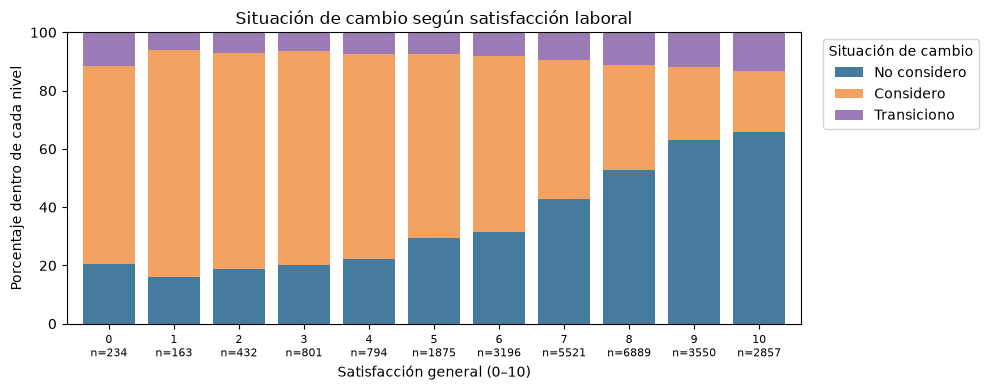

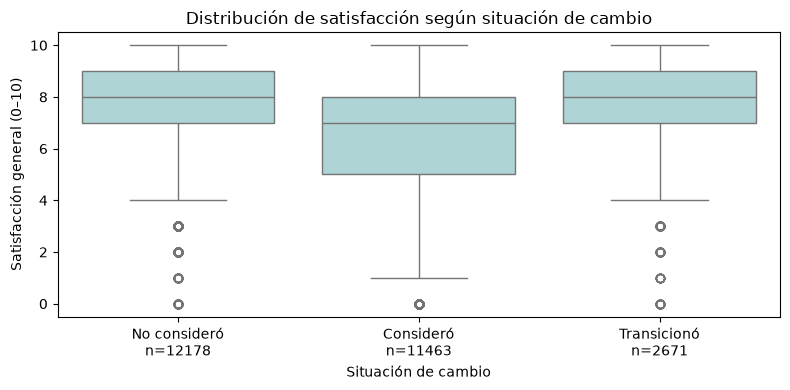

Lectura: quienes consideraron cambiar tienen satisfacción mediana 7/10, frente a 8/10 entre quienes no lo consideraron y 8/10 entre quienes ya transicionaron.
Hay asociación entre satisfacción general y situación de cambio; no podemos establecer qué ocurrió primero ni que cambiar haya mejorado la satisfacción.


In [53]:
# Dibujamos los porcentajes dentro de cada nivel, sin confundirlos con cantidades absolutas.
ax = porcentajes_cambio.plot(kind="bar", stacked=True, figsize=(10, 4), color=["#457b9d", "#f4a261", "#9b7bb5"], width=0.8)
# Contamos cuántas respuestas hay detrás de cada barra porcentual.
cantidades_por_nivel = tabla_cambio.sum(axis=1)
# Mostramos el nivel y su cantidad para no confundir igual altura con igual tamaño de muestra.
etiquetas_niveles = [f"{int(valor)}\nn={int(cantidades_por_nivel.loc[valor])}" for valor in porcentajes_cambio.index]
# Dejamos las etiquetas horizontales para que puedan leerse los once tamaños.
ax.set_xticklabels(etiquetas_niveles, rotation=0, fontsize=8)
# Mantenemos la escala completa del porcentaje.
ax.set_ylim(0, 100)
# Aclaramos el denominador y la variable del eje horizontal.
ax.set(title="Situación de cambio según satisfacción laboral", xlabel="Satisfacción general (0–10)", ylabel="Porcentaje dentro de cada nivel")
# Colocamos la leyenda fuera del área de barras para facilitar la lectura.
ax.legend(title="Situación de cambio", bbox_to_anchor=(1.02, 1), loc="upper left")
# Ajustamos los márgenes incluyendo la leyenda.
plt.tight_layout()
# Mostramos la figura.
plt.show()


# Creamos otra vista de la misma muestra para comparar sus distribuciones de satisfacción.
fig, ax = plt.subplots(figsize=(8, 4))
# Conservamos los tres grupos y sus valores originales de satisfacción.
sns.boxplot(data=df_satisfaccion, x="considers_new_role", y="JobSat", order=orden_cambio, color="#a8dadc", ax=ax)
# Mostramos nombres legibles y el tamaño de cada grupo.
ax.set_xticks(range(3), labels=[f"{etiqueta}\nn={int(cantidad)}" for etiqueta, cantidad in zip(["No consideró", "Consideró", "Transicionó"], resumen_satisfaccion["n"])])
# Mantenemos el recorrido completo de las puntuaciones de satisfacción.
ax.set_ylim(-0.5, 10.5)
# Identificamos la medida y los grupos representados.
ax.set(title="Distribución de satisfacción según situación de cambio", xlabel="Situación de cambio", ylabel="Satisfacción general (0–10)")
# Ajustamos los márgenes y mostramos la segunda figura.
plt.tight_layout()
plt.show()

# Guardamos el resultado de independencia para el resumen final.
apoyo_c = p_c < alpha
# Recuperamos la mediana de quienes no consideraron un cambio.
sat_no_considero = resumen_satisfaccion.loc["No considero", "mediana"]
# Recuperamos la mediana de quienes sí consideraron cambiar.
sat_considero = resumen_satisfaccion.loc["Considero", "mediana"]
# Conservamos separada la mediana de quienes ya transicionaron.
sat_transiciono = resumen_satisfaccion.loc["Transiciono", "mediana"]
# Interpretamos una diferencia concreta de satisfacción usando las medianas calculadas.
print(f"Lectura: quienes consideraron cambiar tienen satisfacción mediana {sat_considero:.0f}/10, frente a {sat_no_considero:.0f}/10 entre quienes no lo consideraron y {sat_transiciono:.0f}/10 entre quienes ya transicionaron.")
# Relacionamos la decisión del test con la pregunta, respetando el carácter observacional.
print("Hay asociación entre satisfacción general y situación de cambio; no podemos establecer qué ocurrió primero ni que cambiar haya mejorado la satisfacción." if apoyo_c else "No encontramos evidencia suficiente de asociación entre satisfacción general y situación de cambio.")

#### Alcance de los aspectos laborales

`JobSatPoints_*` ordena cuánto contribuye cada aspecto a la satisfacción. Un ranking menor significa **más importancia relativa**, no más satisfacción. Mostramos la pregunta y el tipo `RO` de los metadatos para comprobar esa interpretación directamente en el archivo de origen.

El contraste anterior responde por la satisfacción general. Aquí describimos prioridades de las mismas personas agrupadas por situación de cambio. Mostramos tanto las medianas como la cantidad de respuestas válidas de cada aspecto, porque los faltantes pueden variar.

**Por qué barras horizontales agrupadas:** hay nombres largos y tres grupos por aspecto. La orientación horizontal facilita leerlos y las tres barras permiten comparar los rankings medianos directamente sobre un eje común. Conservamos el orden del cuestionario y los colores del gráfico anterior. No apilamos los rankings, porque no son partes de un total. Un puesto 8 tampoco significa el doble de importancia que un puesto 4 (Práctica 5, pp. 5–7).

Las barras son descriptivas: no representan niveles de satisfacción por aspecto ni prueban diferencias significativas entre los grupos.

         qname type                                                                                                                                                                                                                                                                                              question
JobSatPoints_1   RO Rank the following attributes of your current professional job in technology according to those that contribute your job satisfaction so that the first is the most important, last is least important (if you just started a new job, consider the job you spent the most time at in the past year):
                                                                                 Mediana                                  n                      
considers_new_role                                                          No considero Considero Transiciono No considero Considero Transiciono
JobSatPoints_1: Control over the level of quality in projects                   

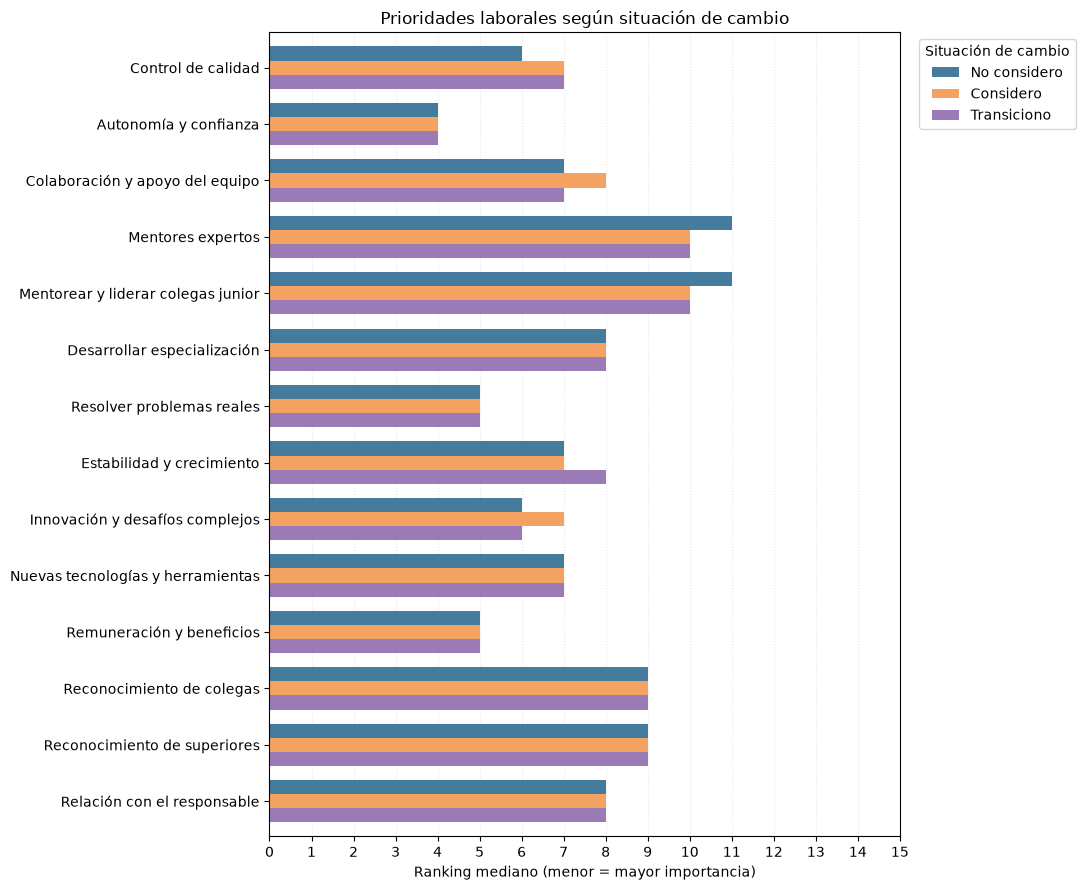

Lectura: coinciden las medianas de los tres grupos en 8 de 14 aspectos; la mayor separación entre medianas es de 1 puesto(s).
En estas respuestas aparecen varias prioridades centrales compartidas. Esto no demuestra igualdad de distribuciones ni satisfacción equivalente con cada aspecto.


In [54]:
# Consultamos una fila del esquema para mostrar qué pregunta originó estos rankings.
meta_aspecto = metadatos[metadatos["qname"].eq("JobSatPoints_1")]
# Mostramos el texto y el tipo de pregunta como evidencia de su interpretación.
print(meta_aspecto[["qname", "type", "question"]].to_string(index=False))
# Seleccionamos los catorce aspectos conservados, en el orden del cuestionario.
columnas_aspectos = [col for col in preprocessed_dataset.columns if col.startswith("JobSatPoints_")]
# Calculamos la mediana de cada ranking por grupo usando las personas del análisis general.
medianas_aspectos = df_satisfaccion.groupby("considers_new_role")[columnas_aspectos].median().reindex(orden_cambio).T
# Contamos las respuestas válidas de cada aspecto en cada grupo.
cantidades_aspectos = df_satisfaccion.groupby("considers_new_role")[columnas_aspectos].count().reindex(orden_cambio).T
# Recuperamos las etiquetas de cada aspecto desde los metadatos originales.
nombre_aspectos = metadatos.set_index("qname")["sub"].to_dict()
# Guardamos etiquetas breves en español para leer el gráfico sin cambiar las variables ni los cálculos.
etiquetas_aspectos = {"JobSatPoints_1": "Control de calidad", "JobSatPoints_2": "Autonomía y confianza", "JobSatPoints_3": "Colaboración y apoyo del equipo", "JobSatPoints_4": "Mentores expertos", "JobSatPoints_5": "Mentorear y liderar colegas junior", "JobSatPoints_6": "Desarrollar especialización", "JobSatPoints_7": "Resolver problemas reales", "JobSatPoints_8": "Estabilidad y crecimiento", "JobSatPoints_9": "Innovación y desafíos complejos", "JobSatPoints_10": "Nuevas tecnologías y herramientas", "JobSatPoints_11": "Remuneración y beneficios", "JobSatPoints_13": "Reconocimiento de colegas", "JobSatPoints_14": "Reconocimiento de superiores", "JobSatPoints_16": "Relación con el responsable"}
# La tabla conserva los nombres originales de los metadatos para verificar las traducciones.
tabla_aspectos = pd.concat({"Mediana": medianas_aspectos, "n": cantidades_aspectos}, axis=1)
# Mostramos junto al código el nombre original que define cada aspecto.
tabla_aspectos.index = [f"{col}: {nombre_aspectos.get(col, col)}" for col in columnas_aspectos]
# Dejamos visibles todos los números que se representan, con su tamaño efectivo.
print(tabla_aspectos.to_string())
# Solo cambiamos etiquetas de la vista para el gráfico, no las de la base.
aspectos_para_grafico = medianas_aspectos.rename(index=etiquetas_aspectos)
# Dibujamos una barra por grupo junto a cada aspecto, sin apilar sus rankings.
ax = aspectos_para_grafico.plot(kind="barh", figsize=(11, 9), color=["#457b9d", "#f4a261", "#9b7bb5"], width=0.75)
# Dejamos el primer aspecto del cuestionario arriba para seguir el mismo orden de la tabla.
ax.invert_yaxis()
# Usamos un mismo eje para los tres grupos y todos los aspectos.
ax.set_xlim(0, 15)
# Mostramos posiciones enteras para recordar que se trata de un ordenamiento.
ax.set_xticks(range(0, 16))
# Indicamos explícitamente cómo se interpreta un ranking menor.
ax.set(title="Prioridades laborales según situación de cambio", xlabel="Ranking mediano (menor = mayor importancia)", ylabel="")
# Ubicamos la leyenda sin tapar las barras.
ax.legend(title="Situación de cambio", bbox_to_anchor=(1.02, 1), loc="upper left")
# Una grilla tenue ayuda a comparar las longitudes con los puestos del ranking.
ax.grid(axis="x", linestyle=":", alpha=0.3)
# Colocamos esa grilla por debajo de las barras.
ax.set_axisbelow(True)
# Ajustamos los márgenes para que entren las etiquetas de los catorce aspectos.
plt.tight_layout()
# Mostramos el gráfico construido con la tabla anterior.
plt.show()

# Contamos los aspectos con medianas informadas e iguales en los tres grupos.
aspectos_con_mediana_comun = int((medianas_aspectos.notna().all(axis=1) & medianas_aspectos.nunique(axis=1).eq(1)).sum())
# Medimos la separación máxima entre las medianas de un mismo aspecto.
mayor_separacion_ranking = (medianas_aspectos.max(axis=1) - medianas_aspectos.min(axis=1)).max()
# Leemos un patrón del gráfico sin inventar puestos ni confundirlos con intensidad de satisfacción.
print(f"Lectura: coinciden las medianas de los tres grupos en {aspectos_con_mediana_comun} de {len(medianas_aspectos)} aspectos; la mayor separación entre medianas es de {mayor_separacion_ranking:.0f} puesto(s).")
# Limitamos el resultado a las prioridades resumidas por estas medianas.
print("En estas respuestas aparecen varias prioridades centrales compartidas. Esto no demuestra igualdad de distribuciones ni satisfacción equivalente con cada aspecto.")

### 4.7. Resumen de los contrastes

La tabla siguiente reúne las seis preguntas. Se construye con los tamaños, medidas y decisiones calculados en las secciones anteriores. El `n` es el total utilizado en cada análisis, que puede cambiar según las respuestas disponibles. Para países y perfiles, el desglose de cada grupo queda en sus tablas de origen.

La confianza en IA se evalúa descriptivamente mediante agrupaciones y porcentajes. Para el perfil por edad, cada condición conserva su prueba y no reunimos sus p-valores en uno solo. Para la hipótesis C, el contraste se refiere a satisfacción general; las prioridades laborales se describen por separado.

En la fila de satisfacción, las tres medianas se presentan en este orden: **no consideró / consideró / transicionó**.

In [55]:
# Reunimos resultados ya calculados: esta tabla no vuelve a filtrar ni modifica los datos.
resumen_hipotesis = pd.DataFrame([
    {"Hipótesis": "Confianza en IA", "n": n_aiacc, "Resultado observado": f"Alta {100 * p_alta:.2f}%; desconfianza {100 * p_desconfianza:.2f}%", "Conclusión y alcance": "Se cumplen ambas condiciones en la muestra" if cumple_h1 else "No se cumplen ambas condiciones en la muestra"},  # Evaluación descriptiva de las respuestas agrupadas.
    {"Hipótesis": "Estados Unidos–India", "n": len(df_paises), "Resultado observado": f"Mediana USA/India = {ratio_mediana:.2f}", "Conclusión y alcance": "Compatible con superar el doble" if apoyo_h2 else "No se sostiene superar el doble"},  # El cociente sale de las medianas por país.
    {"Hipótesis": "Perfil por edad", "n": len(df_multi), "Resultado observado": f"IA: diferencia {diferencia_ia_pp:.2f} puntos", "Conclusión y alcance": "Apoyo a las tres condiciones del perfil" if apoyo_multi else "Apoyo insuficiente al perfil completo"},  # También se contrastaron experiencia y compensación.
    {"Hipótesis": "Argentina–SMVM", "n": n_arg, "Resultado observado": f"Mediana USD {mediana_arg:,.2f}", "Conclusión y alcance": "Supera tres SMVM del escenario fijado" if apoyo_a else "No se demuestra superar el umbral"},  # La referencia se mantiene fija en la sección 4.4.
    {"Hipótesis": "Experiencia–confianza", "n": len(df_exp_ia), "Resultado observado": f"Spearman ρ = {rho_exp_confianza:.3f}", "Conclusión y alcance": "Asociación significativa, muy débil" if apoyo_b else "Sin diferencias globales detectadas"},  # Kruskal compara distribuciones; Spearman mide tendencia.
    {"Hipótesis": "Satisfacción–cambio", "n": len(df_satisfaccion), "Resultado observado": f"Medianas: {sat_no_considero:.0f} / {sat_considero:.0f} / {sat_transiciono:.0f}", "Conclusión y alcance": "Asociación en satisfacción general" if apoyo_c else "Asociación general no detectada"},  # Orden: no consideró, consideró, transicionó.
])
# Mostramos las seis filas sin perder la referencia a los análisis que las originaron.
resumen_hipotesis

,Hipótesis,n,Resultado observado,Conclusión y alcance
0,Confianza en IA,25739,Alta 2.74%; desconfianza 45.94%,Se cumplen ambas condiciones en la muestra
1,Estados Unidos–India,5319,Mediana USA/India = 8.07,Compatible con superar el doble
2,Perfil por edad,19434,IA: diferencia 6.35 puntos,Apoyo a las tres condiciones del perfil
3,Argentina–SMVM,136,"Mediana USD 40,473.50",Supera tres SMVM del escenario fijado
4,Experiencia–confianza,25120,Spearman ρ = -0.041,"Asociación significativa, muy débil"
5,Satisfacción–cambio,26312,Medianas: 8 / 7 / 8,Asociación en satisfacción general


### 4.8. Discusión y límites

Las diferencias de compensación y el perfil por edad muestran patrones entre grupos de profesionales. Esos grupos también pueden variar en país, rol, empresa y trayectoria. La comparación no separa esos efectos ni describe cómo cambiaría una misma persona con el paso del tiempo.

En experiencia y confianza encontramos una asociación muy débil. Por eso, la significancia estadística se interpreta junto con el coeficiente y la superposición de las distribuciones: un p pequeño no convierte la experiencia en un factor que determine la confianza.

La comparación argentina utiliza la mediana y una referencia de SMVM y cotización fijada por el grupo. Como combina compensaciones de la encuesta 2025 con una referencia posterior, responde a ese escenario y no a una medición del poder adquisitivo en un mismo período. En satisfacción, `JobSat` permite estudiar la relación general con el cambio laboral; los rankings solo describen importancia relativa de los aspectos.

Las comprobaciones de sensibilidad acompañan los análisis principales. Conservamos las compensaciones informadas y dejamos explícitas las dudas de unidad o carga que no podemos resolver. Una señal IQR o una respuesta dudosa en una columna no invalida automáticamente toda la fila. Los valores 10000 de herramientas de trabajo se trataron como desconocidos solo en ese campo, conservando el resto de las respuestas.

La encuesta es voluntaria y los faltantes pueden depender del perfil. Los contrastes no corrigen ese sesgo ni prueban causalidad. Cada p-valor corresponde a la prueba indicada; tampoco presentamos las seis preguntas como una única prueba con error global del 5%.

### Referencias de los métodos

- **Clase 2 – Análisis, limpieza y exploración de datos:** incoherencias, unidades, faltantes y sesgos de selección.
- **Práctica 4 – Python y Práctico 4 de 2026:** `copy`, `drop`, `replace`, `map`, variables derivadas y decisiones según el dominio.
- **Clase 3 – Acceso y análisis:** IQR/boxplots, Spearman y chi-cuadrado de independencia.
- **Práctica 5 – Visualización:** histogramas, boxplots, barras y lectura de distribuciones.
- **Clase 5 – Tests paramétricos y no paramétricos:** hipótesis, significancia, proporciones, Student, supuestos, mediana, Kruskal-Wallis y ANOVA.
- **Práctica 9 – Regresión lineal, pp. 18–19:** diagnóstico con Shapiro y advertencia sobre tamaños grandes. Aquí no ajustamos una regresión ni necesitamos un QQ-plot salarial.
- [Metodología de la encuesta 2025](https://survey.stackoverflow.co/2025/methodology): reclutamiento voluntario y conversión original de monedas.
- [Documentación de `median_test`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.median_test.html), [Shapiro](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.shapiro.html) y [chi-cuadrado](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.chi2_contingency.html): detalles de implementación de los métodos vistos en clase.